### 1st cell

In [1]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from scipy.interpolate import RegularGridInterpolator

### 2nd PDE, grid and exact solution
Advection–diffusion with a sign-changing speed: $u_t + a(x)\,u_x = \alpha u_{xx}$, $a(x) = C(x - x_0)$, $C=-3$, $x_0=0.5$, $\alpha=0.01$, on $[0,1]$.
The flow converges on $x_0$: characteristics lean right for $x<x_0$ and left for $x>x_0$. $u(x,0)=1+0.8\cos(2\pi(x-0.3)/1.5)$, exact Dirichlet data at both (inflow) walls.
Exact solution: $u(x,t)=\mathbb E[u_0(Y_t)]$, $Y$ an Ornstein–Uhlenbeck path from $x$, Gaussian with mean $x_0+(x-x_0)e^{-Ct}$ (the characteristic foot) and variance $\alpha(1-e^{-2Ct})/C$.
The exact solution is only used to check results, never by the agent.

advection: alpha = 0.01, a(x) = -3 (x - 0.5), T = 0.5 | nx = 50, nt = 56, dx = 0.02041, dt = 9.091e-03 | r = 0.22, nu_max = 0.67, 2r + nu^2 = 0.88
check: PDE residual of the closed form, max over x: 1.2e-06
check: FD on a grid 1x finer vs u_true at t = 0.25: max error 2.8e-02
check: FD on a grid 2x finer vs u_true at t = 0.25: max error 8.4e-03
check: FD on a grid 4x finer vs u_true at t = 0.25: max error 2.1e-03


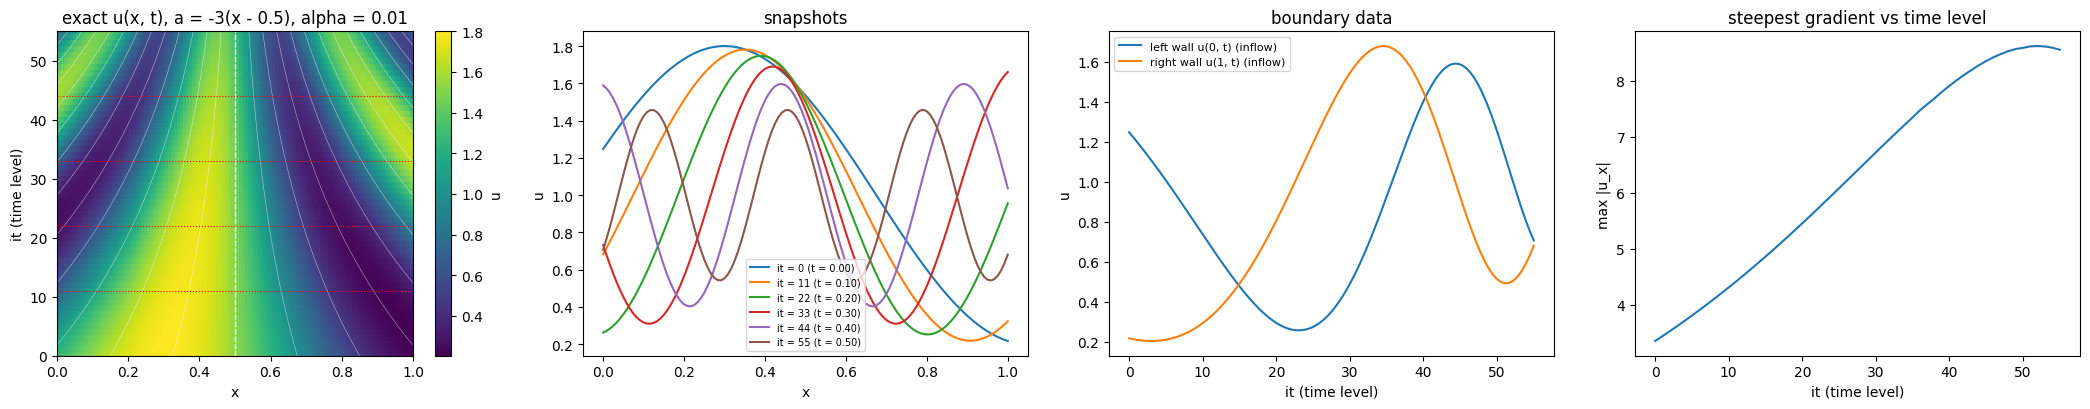

In [2]:
# ── Problem: advection-diffusion with a speed that changes sign at X0 ──
#   u_t + a(x) u_x = alpha u_xx,  a(x) = C_OU (x - X0)  on [0, 1]
#   C_OU < 0: the flow converges on X0 (a > 0 left of X0, a < 0 right of it): characteristics lean right on the left side,
#   left on the right side, and a steep region forms at X0. Both walls are inflow; their data is the exact solution.
PROBLEM = "advection"
alpha, T = 0.01, 0.5
C_OU, X0 = -3.0, 0.5
speed = lambda x: C_OU * (np.asarray(x, dtype=float) - X0)      # a(x); linear, so a' = C_OU and a'' = 0
A_MAX = abs(C_OU) * max(X0, 1 - X0)                              # max |a| on [0, 1]

C_BG, A_W, L_W, X_PK = 1.0, 0.8, 1.5, 0.3                        # IC: peak at 0.3, so the structure crosses the sign change
K_W = 2 * np.pi / L_W
u0 = lambda x: C_BG + A_W * np.cos(K_W * (np.asarray(x, dtype=float) - X_PK))

# ── Grid ──
# explicit advection + diffusion (LW, FD-3) is stable for 2r + nu^2 <= 1, r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (closed form) ──
#   u(x, t) = E[u0(Y_t)], Y = Ornstein-Uhlenbeck path from x: dY = -a(Y) ds + sqrt(2 alpha) dW  (backward Kolmogorov)
#   Y_t is Gaussian: mean m = X0 + (x - X0) e^{-C_OU t} (the foot of the characteristic), variance v = alpha (1 - e^{-2 C_OU t}) / C_OU
#   and E[cos(k (Y - X_PK))] = cos(k (m - X_PK)) e^{-k^2 v / 2}.  Valid on the whole line, so also outside [0, 1].
def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    m = X0 + (x - X0) * np.exp(-C_OU * t)
    v = alpha * (1 - np.exp(-2 * C_OU * t)) / C_OU
    return C_BG + A_W * np.exp(-K_W**2 * v / 2) * np.cos(K_W * (m - X_PK))

# exact values on the grid, one time level at a time when first needed (u_true ONLY for checks, reports, and wall data)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data: u at x = 0 and x = 1 as functions of t (given data, like the IC) ──
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])            # (time, [left, right])
_gs = CubicSpline(_tb, _gb)
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"{PROBLEM}: alpha = {alpha}, a(x) = {C_OU:g} (x - {X0:g}), T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

# ── Checks: the closed form solves the PDE; an explicit FD solve on finer grids converges to it (error / 4 per halving) ──
_x, _t, _h = np.linspace(0, 1, 11), 0.3 * T, 1e-4
_res = ((u_true(_x, _t + _h) - u_true(_x, _t - _h)) / (2 * _h) + speed(_x) * (u_true(_x + _h, _t) - u_true(_x - _h, _t)) / (2 * _h)
        - alpha * (u_true(_x + _h, _t) - 2 * u_true(_x, _t) + u_true(_x - _h, _t)) / _h**2)
print(f"check: PDE residual of the closed form, max over x: {np.abs(_res).max():.1e}")
def _fd_fine(k, t_end):
    n, h = (nx - 1) * k + 1, dx / k
    steps = int(np.ceil(t_end / min(0.2 * h**2 / alpha, 0.5 * h / A_MAX))); s = t_end / steps
    u, ai = u0(np.arange(n) * h), speed(np.arange(1, n - 1) * h)
    for j in range(steps):
        u[1:-1] = u[1:-1] + alpha * s / h**2 * (u[2:] - 2 * u[1:-1] + u[:-2]) - ai * s / (2 * h) * (u[2:] - u[:-2])
        u[0], u[-1] = g_left((j + 1) * s), g_right((j + 1) * s)
    return u[::k]
_t_chk = 0.5 * T
for k in (1, 2, 4):
    print(f"check: FD on a grid {k}x finer vs u_true at t = {_t_chk:.2f}: max error {np.abs(_fd_fine(k, _t_chk) - u_true(x_grid, _t_chk)).max():.1e}")

# ── Pictures: u(x, t) with characteristics, snapshots, boundary data, steepest gradient (time in levels it = t / dt) ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u")
for x_0 in np.linspace(-3, 4, 41):                                   # characteristics x = X0 + (x_0 - X0) e^{C_OU t}
    axes[0].plot(X0 + (x_0 - X0) * np.exp(C_OU * its * dt), its, "w-", lw=0.4, alpha=0.6)
axes[0].axvline(X0, color="w", ls="--", lw=1)
snap = np.linspace(0, nt - 1, 6).round().astype(int)
for it in snap:
    axes[0].axhline(it, color="r", ls=":", lw=0.8)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, nt - 1)
axes[0].set_xlabel("x"); axes[0].set_ylabel("it (time level)"); axes[0].set_title(f"exact u(x, t), a = {C_OU:g}(x - {X0:g}), alpha = {alpha}")
for it in snap:
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it} (t = {it * dt:.2f})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="left wall u(0, t) (inflow)")
axes[2].plot(_tb / dt, _gb[:, 1], label="right wall u(1, t) (inflow)")
axes[2].set_xlabel("it (time level)"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
axes[3].plot(its, np.abs(np.gradient(Uxt, xf, axis=1)).max(axis=1))
axes[3].set_xlabel("it (time level)"); axes[3].set_ylabel("max |u_x|"); axes[3].set_title("steepest gradient vs time level")
plt.tight_layout(); plt.show()

In [3]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a(x) u_x substituted ──
#   neighbour q at offset (DX, DT) from p, speed a = a(x_p):
#     u_q ~ u + [xi - a' DT (DX - a DT / 2)] u_x + [xi^2 / 2 + alpha DT] u_xx,   xi = DX - a DT
#   the a' term comes from the speed changing across the stencil (u_xt and u_tt carry a' u_x)
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = speed at p.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    r1 = xi - C_OU * DT * (DX - 0.5 * a_loc * DT)                     # u_x row with the a' term
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), r1 / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value $u_q$ in a Taylor series around $p$ (and using $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
where $P_p$ is the Taylor polynomial of $u$ around $p$, kept up to weight 4 (a $\Delta t$ counts like two $\Delta x$'s, since $\alpha\Delta t\sim\Delta x^2$):
$$P_p=u_x\Delta x+u_t\Delta t+\tfrac12u_{xx}\Delta x^2+u_{xt}\Delta x\Delta t+\tfrac12u_{tt}\Delta t^2+\tfrac16u_{xxx}\Delta x^3+\tfrac12u_{xxt}\Delta x^2\Delta t+\tfrac1{24}u_{xxxx}\Delta x^4 .$$
Every time derivative is replaced using Burgers ($u_t=\alpha u_{xx}-u\,u_x$), so only the space derivatives $u,u_x,\dots,u_{xxxx}$ at $p$ are needed:

| | |
|---|---|
| $u_t$ | $\alpha u_{xx}-u\,u_x$ |
| $u_{xt}$ | $\alpha u_{xxx}-u\,u_{xx}-u_x^2$ |
| $u_{xxt}$ | $\alpha u_{xxxx}-u\,u_{xxx}-3u_xu_{xx}$ |
| $u_{tt}$ | $\alpha^2u_{xxxx}-2\alpha u\,u_{xxx}+u^2u_{xx}+2u_x(u\,u_x-2\alpha u_{xx})$ |

The terms with $u_x^2$ and $u_xu_{xx}$ come from the nonlinear term: the speed $u$ changes across the stencil. A score built for the linear equation (frozen speed) misses them.
Check: random admissible stencils at random points below $z^*$, with the **exact** derivatives (from the exact solution), score against the true local error.

300 admissible stencils, |u_x| from 0.04 to 8.62
corr(log score, log true error) = 0.98, median |score - true error| / true error = 0.03


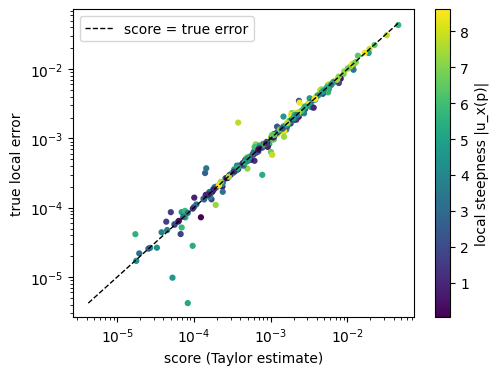

In [4]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients, every time derivative replaced using the PDE, one derivative at a time:
#   (d/dx)^n u_t = alpha u^(n+2) - a u^(n+1) - n a' u^(n)        (a'' = 0; x-derivatives above the 4th taken as 0)
# Terms kept up to total degree 4 in (dx, dt): here a dt is a cell (a dt ~ dx), not dx^2 as in a diffusion-dominated problem.
from math import factorial
DEG = 4
def taylor_coeffs(d, ap):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p, ap = a(x_p). Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for 0 < i + j <= DEG."""
    D, n = [np.array(d, dtype=float)], np.arange(5)
    for _ in range(DEG):
        P = np.r_[D[-1], 0.0, 0.0]
        D.append(alpha * P[2:] - ap * P[1:-1] - n * C_OU * P[:-2])
    return {(i, j): D[j][i] / (factorial(i) * factorial(j)) for j in range(DEG + 1) for i in range(5) if 0 < i + j <= DEG}

def score(DX, DT, w, d, ap):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d, ap).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, for random admissible stencils at random points p anywhere in the domain ──
# here the derivatives are exact (u_true ONLY for this check); colour = local steepness |u_x|
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]
S, D, G = [], [], []
while len(S) < 300:
    p = (int(rng.integers(3, nx - 3)), int(rng.integers(3, nt)))
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    ap = float(speed(p[0] * dx))
    w = solve_weights(DX, DT, ap)
    if w is None:
        continue
    d = x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S.append(score(DX, DT, w, d, ap)); D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S, D, G = np.array(S), np.array(D), np.array(G)
print(f"300 admissible stencils, |u_x| from {G.min():.2f} to {G.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=G, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

### Rough guess of u and its derivatives
To build the map backward, every point needs, before any value has been computed:
- its local speed $a=u$ (for the weights), and
- the space derivatives $u,u_x,\dots,u_{xxxx}$ (for the score, cell 4).

We take them from a cheap **coarse solve**: Lax–Wendroff on a grid 5× coarser, from the initial condition to $T$, computed once for all queries. At each coarse time, a sine series is fitted through the coarse values ($u=0$ at both walls), which gives the derivatives exactly for the fit. In time we interpolate linearly onto our grid.
The guess only steers **which stencils and weights are chosen**. The values at $z^*$ are computed from the neighbours' values, so a poor guess gives worse choices, never wrong numbers. Its cost (840 points) is added to the method's cost.

coarse grid: 25 x 24 = 600 points (dx 0.0417, dt 2.17e-02)
all points   : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.003  0.013  0.016  0.031  0.053
10% steepest : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.003  0.030  0.061  0.040  0.192


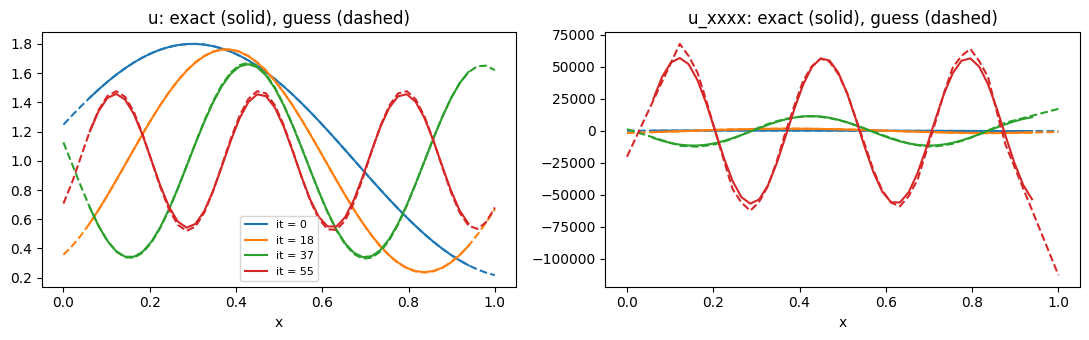

In [5]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (score, influence); the speed a(x) is known exactly ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the initial condition to T, with the same boundary data; computed once.
K_COARSE = 2
from scipy.interpolate import make_interp_spline
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
_c2, _c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                 # same stability rule as the main grid
tau = T / int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2))))
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
ac  = speed(xc[1:-1])
for j in range(1, len(tc)):
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, ac * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (1 - C_OU * tau / 2) * (u[2:] - u[:-2])   # LW, with the a a' u_x dt^2/2 term
    n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
    Uc.append(n)
G_COARSE = len(xc) * len(tc)                                                  # cost of the guess (grid points)

# ── Smooth fit in x at each coarse time: a quintic spline through the coarse values, differentiated exactly ──
Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    sp = make_interp_spline(xc, u, k=5)
    for k in range(5):
        Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)

# ── Linear in time onto our grid: GUESS[k, it, ix] = k-th x-derivative of the guess at grid point (ix, it) ──
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f  = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                 # (u, u_x, u_xx, u_xxx, u_xxxx) at q

# ── Check: guess vs exact at 300 random points, for all of them and for the 10% steepest (u_true ONLY for this check) ──
print(f"coarse grid: {len(xc)} x {len(tc)} = {G_COARSE} points (dx {hc:.4f}, dt {tau:.2e})")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(3, nx - 3)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex) + 1e-12)
steep = np.abs(ex[:, 1]) >= np.quantile(np.abs(ex[:, 1]), 0.9)
for name, sel in [("all points", slice(None)), ("10% steepest", steep)]:
    print(f"{name:13s}: median relative error for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.3f}" for v in np.median(rel[sel], axis=0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, it in enumerate([0, nt // 3, 2 * nt // 3, nt - 1]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes, [0, 4]):
        ax.plot(x_grid[3:-3], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
for ax in axes: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Backward map and influence β
**The map.** Start at $z^*$ and give it a stencil. Each neighbour that is not known data (IC or wall) becomes a new point that also needs a stencil. Repeat until every branch ends on the IC or a wall. Points are expanded **latest $t$ first**.

**Weights.** No values exist yet while building, so each point $p$ takes its speed from the guess (cell 5), $a_p=u_{\rm guess}(p)$, rounded to steps of 0.02 so the weights can be cached by (shape, speed). Its score uses the guessed derivatives at $p$ (cell 4).

**Influence.** $\beta_p$ = how much an error at $p$ changes the value at $z^*$. Start with $\beta_{z^*}=1$. When $p$ is expanded with weights $w$, pass its influence down: $\beta_q \mathrel{+}= \beta_p\,w_q$.

**Forward pass.** Values are computed bottom-up from the IC and walls, $\hat u_p=\sum_q w_q\hat u_q$, **with the weights chosen in the map**. Recomputing them with another speed would undo the choice: the score was computed for exactly these weights. The guess shapes the stencils and weights, but no guessed value enters $\hat u$.

**Exact identity.** With $\delta_p=u_p-\sum_q w_qu_q$ the local error,
$$e(z^*)=\sum_p\beta_p\,\delta_p .$$
Check: give every point the Lax–Wendroff stencil; the identity must hold to all digits.

In [6]:
# ── Known data: the initial condition and the walls are given, not computed ──
# their values are the exact solution there: u0 at t = 0, the boundary data g_left / g_right on the walls
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug

# ── Speed at p for its weights: a(x) is known exactly ──
a_build = lambda p: float(speed(p[0] * dx))

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed). Solved with the neighbours sorted (latest level first, then left to right), so the
    result never depends on the order the neighbours were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]                  # back to the order of nbs
    return w

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p), a_build(p))

#   SAME_LEVEL = k > 0 adds the cells (-1, 0) .. (-k, 0): neighbours on p's OWN time level, to its left (upwind for u > 0).
#   To stay explicit (no linear solve): within a level, values are computed LEFT to right (left neighbours are ready),
#   and points are expanded RIGHT to left (every user of a point has passed its influence down before the point is
#   expanded, so beta stays exact). SAME_LEVEL = 0 restores the original window and order (needed for the old agents).
SAME_LEVEL = 0
ORDER = -1 if SAME_LEVEL else 1                      # sign of ix in the pending heap: -1 = right to left within a level

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded LATEST t first (and, within a level, in the order above): every point that can
# use p is expanded before p, so p's influence beta_p is complete when p is expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], ORDER * z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def pending_points(m):
    """The pending points as (ix, it)."""
    return [(ORDER * k, -it) for it, k in m["pending"]]
# ── Same-level neighbours on BOTH sides ──
#   SAME_LEVEL = k > 0 adds the cells (-k..-1, 0) and (1..k, 0): neighbours on p's own time level, left AND right.
#   No linear solve: within a level the same-level links must form no cycle (a mask forbids any link that would close one),
#   so the level can be computed in dependency order. Because a point's same-level users can come after it, its influence
#   beta is only final when its whole level is done: beta is passed down ONE LEVEL AT A TIME, when the level is complete.
#   SAME_LEVEL = 0 gives back the original window (needed for the old agents).

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded latest t first, left to right within a level. Stencils are chosen point by
# point; when the last point of a level is expanded, the level is "closed": its beta is passed down (users before the
# points they use), which completes the beta of the lower points before they are expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {},
            "same": {}, "level": []}               # same: p -> same-level points p uses | level: expanded points of the open level

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def reaches(m, a, b):
    """True if same-level point a uses b, directly or through other same-level points."""
    stack, seen = [a], set()
    while stack:
        q = stack.pop()
        if q == b:
            return True
        if q not in seen:
            seen.add(q); stack.extend(m["same"].get(q, []))
    return False

def forbidden(m, p):
    """Window cells p may not use: same-level points that already use p (directly or not), which would close a cycle."""
    return [k for k in range(N_CELLS) if WINDOW[k][1] == 0 and not is_known(place(p, k)) and reaches(m, place(p, k), p)]

def users_first(m, pts):
    """The points of one level ordered so that every point comes before the same-level points it uses."""
    pts, order, done = set(pts), [], set()
    def visit(q):                                  # depth-first: a point is placed after all its same-level users
        if q in done:
            return
        done.add(q)
        for r in pts:
            if q in m["same"].get(r, []):
                visit(r)
        order.append(q)
    for q in sorted(pts):
        visit(q)
    return order

def close_level(m):
    """Pass the open level's beta down (users first) and return the level's points (their beta is now final)."""
    pts = m["level"]
    for p in users_first(m, pts):
        nbs, w = m["stencil"][p]
        for q, wq in zip(nbs, w):
            if not is_known(q):
                m["beta"][q] += m["beta"][p] * wq
    m["level"] = []
    return pts

def expand(m, nbs):
    """Give the next point the stencil nbs. Returns (p, w, closed): closed = the points whose beta became final now."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    m["same"][p] = [q for q in nbs if q[1] == p[1] and not is_known(q)]
    for q in nbs:
        if not is_known(q) and q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
    m["level"].append(p)
    level_done = not m["pending"] or m["pending"][0][0] != it
    return p, w, (close_level(m) if level_done else [])

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p (it must respect forbidden(m, p))."""
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

# ── Forward pass: values bottom-up; within a level, every point after the same-level points it uses ──
# The map fixes the neighbours (chosen with the guessed speed). Each point then re-solves its weights with the speed
# of its own computed value (picard steps; 0 = keep the map's weights), so the guessed speed never enters the values.
# The weights actually used are kept in m["w_used"] (report needs them).
def forward_order(m):
    order = []
    for t in sorted({p[1] for p in m["stencil"]}):
        order += users_first(m, [p for p in m["stencil"] if p[1] == t])[::-1]
    return order

def evaluate(m, picard=0):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in forward_order(m):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, a_build(p))           # the speed is exact: picard steps change nothing here
            if w_new is None:
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat

# ── Check: every point takes the Lax-Wendroff stencil (3 points one level down) ──
# z* = (20, 40) is close enough to the left wall that its cone reaches it: the wall data is used.
# The identity only holds if the known data (IC and walls) is exact.
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]
z = (10, 40)
m = build_map(z, lw)
err = Ug(z) - evaluate(m, picard=0)[z]                       # the map's own weights: the identity must hold exactly
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
n_wall = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[0] in (0, nx - 1) and q[1] > 0)
print(f"LW map at z* = {z}: {len(m['stencil'])} points, {n_wall} uses of wall data | error at z* {abs(err):.2e}")
print(f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")
print(f"with live speed (1 Picard step): error at z* {abs(Ug(z) - evaluate(m)[z]):.2e}")

LW map at z* = (10, 40): 1134 points, 31 uses of wall data | error at z* 4.05e-03
identity: e(z*) = 4.050592e-03, sum beta*delta = 4.050592e-03
with live speed (1 Picard step): error at z* 4.05e-03


### Window, admissible stencils and the mask
**Window.** The candidate neighbours of $p$ are the 21 cells up to 3 to each side and 1 to 3 levels below $p$. A cell past a wall or below $t=0$ is moved onto the wall or the IC (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the admissibility test (cell 3), with $p$'s guessed speed. Points with the same local situation (distance to walls/IC) and the same guessed speed share one list, computed once and cached together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$. The score at a point is then just these moments times the Taylor coefficients at that point (cell 4): one small product per point.
**Mask.** The agent will pick the 5 cells one at a time. A cell may be picked next only if some admissible stencil contains it together with the picks so far, so the agent can never end up with a bad stencil.
**First rule without RL:** every point takes its lowest-score stencil. **Report** gives a finished map's points, its true error at $z^*$ and its exact bound $\sum_p|\beta_p\delta_p|$ (exact solution used only for reporting).

21 window cells | interior point (25, 40): 18734 admissible stencils of 20349
first pick allowed on 21 cells
LW          : 1344 points, error 1.91e-03, exact bound 2.43e-03  (0 s)
lowest score: 1529 points, error 1.16e-04, exact bound 3.95e-04  (9 s)


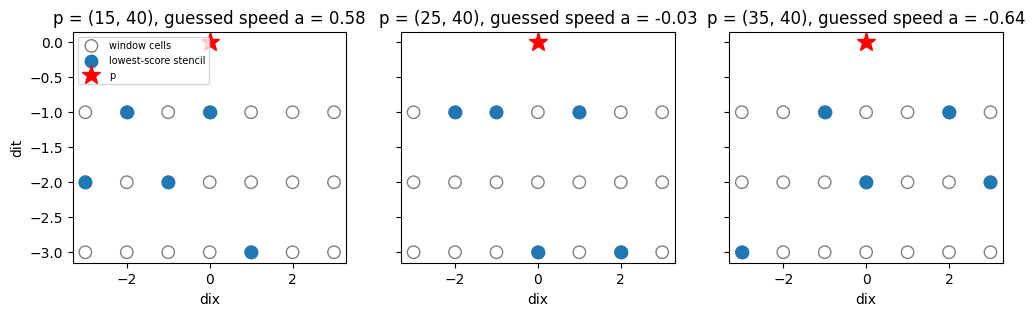

In [7]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = ([(k, 0) for k in list(range(-SAME_LEVEL, 0)) + list(range(1, SAME_LEVEL + 1))]
           + [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)])
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5, 0.0))                          

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p), a_build(p))       
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def allowed_sets(m, p):
    """Admissible stencils at p that use no forbidden (cycle-closing) cell: (sets, uses, scores) restricted to them.
    Cached on the map for the current point (it only changes when a stencil is placed), so the 5 picks of a point share it."""
    key = (p, len(m["stencil"]))
    if m.get("_allowed_key") != key:
        sets, uses, sc = admissible(p)
        bad = forbidden(m, p)
        ok = ~uses[:, bad].any(axis=1) if bad else np.ones(len(sets), dtype=bool)
        m["_allowed"] = ([s for s, o in zip(sets, ok) if o], uses[ok], sc[ok]) if bad else (sets, uses, sc)
        m["_allowed_key"] = key
    return m["_allowed"]

def pick_mask(m, p, picks):
    """Cell k may be picked next if some allowed stencil contains the picks so far plus k."""
    _, uses, _ = allowed_sets(m, p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = allowed_sets(m, p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# with the weights the forward pass actually used (live speed); beta is recomputed with them, so e(z*) = sum beta delta
def report(m):
    """Points, true error at z*, exact bound sum |beta delta| with the weights the forward pass used (u_true ONLY here)."""
    z = m["z_star"]
    u_hat, W = evaluate(m), m["w_used"]
    beta = {z: 1.0}
    for p in forward_order(m)[::-1]:                              # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}
z = (25, 40)
sets, _, sc = admissible(z)
print(f"{N_CELLS} window cells | interior point {z}: {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))}")
print("first pick allowed on", pick_mask(start_map(z), z, []).sum(), "cells")
for name, rule in [("LW", lw), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(15, 40), (25, 40), (35, 40)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

In [8]:
def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

### Environment
**Episode.** Build one map for the query $z^*$. At each step the agent picks one window cell for the current point (the latest-$t$ pending point). After 5 picks the stencil is complete, the point is expanded (cell 6), and the next point comes up. The episode ends when no points are pending.
**Mask.** Only cells that can still complete an admissible stencil are allowed (cell 7). Points with a single admissible stencil (next to the IC) are played automatically.
**Reward**, given each time a stencil is complete:
$$r_p=-\frac{|\beta_p|\,s_p}{B_{\rm LW}}-\lambda\,\frac{\text{new points}}{N_{\rm LW}},$$
where $s_p$ is the score (cell 4, with the guessed derivatives), and $B_{\rm LW}$, $N_{\rm LW}$ are the score sum and point count of the Lax–Wendroff map of the same $z^*$. So the total return is $-B/B_{\rm LW}-\lambda(N-1)/N_{\rm LW}$, and LW itself scores $\approx -1-\lambda$.
**Cap.** If the map grows past $3N_{\rm LW}$ points, the episode stops, and each point left unexpanded costs its worst stencil.
**State**, for the current point $p$:
- per window cell: already picked, already in the map (reusing it is free), known data (IC/wall), and the best score still reachable through it;
- and globally: $\log|\beta_p|$, levels above the IC, offset to $z^*$, pick number, points used so far, and the pending workload (points still waiting and their total influence).

In [9]:
# ── Units of the reward ──
#   accuracy: the estimated error share |beta_p| s_p, in units of EPS (a fixed target error for the problem, same for every query)
#   cost:     new points, in units of N_LW (the point count of the Lax-Wendroff map of the same z*: "a classical solve")
EPS = 1e-3
_nlw_cache = {}
def n_lw(z):
    """Points of the LW map of z* (the cost unit)."""
    if z not in _nlw_cache:
        _nlw_cache[z] = len(build_map(z, lw)["stencil"])
    return _nlw_cache[z]

# ── State switch: per-cell physics features ──
#   STATE_X = True adds, for every window cell q, two numbers to the state:
#     xi_q / dx : the cell's offset from the foot of the characteristic (with p's guessed speed): which side is upwind, how far
#     R_q       : the cell's Taylor remainder, the part of the local Taylor polynomial the three conditions do NOT cancel,
#                 so the score of ANY stencil at p is |sum_q w_q R_q|  (signed log of R_q / dx^3, which spans ~1 .. 1000)
STATE_X = False
def cell_features(p):
    d, ap = guess_derivs(p), a_build(p)
    off = np.array([(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)], dtype=float)
    DX, DT = off[:, 0] * dx, off[:, 1] * dt
    xi = DX - ap * DT
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d, ap).items())   # in cell_features
    R = P - d[1] * xi - d[2] * (0.5 * xi**2 + alpha * DT)
    return np.concatenate([xi / dx, np.sign(R) * np.log10(1 + np.abs(R) / dx**3)])


# ── Environment: one step = one pick; a reward each time a stencil is complete ──
#   reward of a stencil at p:  -|beta_p| s_p / EPS  -  lam * (new points) / N_LW
#   lam (the price of a point) is drawn per episode, log-uniform in lam_range, and shown to the agent
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
N_OBS   = 3 * N_CELLS + 12 + (2 * N_CELLS if STATE_X else 0)

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(0.1, 10.0), cap=3.0):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS)               # one action = one window cell

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self._play_forced()
        return self._obs(), {}

    def _complete(self, cells):
        """Expand the next point with these cells. Reward: the points' cost now; the accuracy terms of a level when it closes."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, _, closed = expand(self.m, nbs)
        return -self._accuracy(closed) - self.lam * n_new / self.N_ref

    def _accuracy(self, pts):
        """Sum of |beta_p| s_p / EPS over points whose beta is final."""
        term = sum(abs(self.m["beta"][q]) * point_score(q, *self.m["stencil"][q]) for q in pts)
        self.B += term
        return term / EPS

    def _play_forced(self):
        """Points with only one allowed stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            sets, _, _ = allowed_sets(self.m, next_point(self.m))
            if len(sets) != 1:
                break
            r += self._complete(sets[0])
        return r

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = [(ix, -it) for it, ix in self.m["pending"]]
        d      = guess_derivs(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam)]                                # price of a point
        feats = [cell_features(p)] if STATE_X else []
        return np.concatenate([picked, exists, known, glob] + feats).astype(np.float32)
    def step(self, k):
        self.picks.append(int(k))
        p = next_point(self.m)
        if len(self.picks) < len(allowed_sets(self.m, p)[0][0]):   # still choosing p's stencil (fewer cells near the walls)
            return self._obs(), 0.0, False, False, {}
        r = self._complete(self.picks)
        self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: close the open level, then each point left unexpanded costs its worst stencil
        r -= self._accuracy(close_level(self.m)) if self.m["level"] else 0.0
        for it, ix in self.m["pending"]:
            q = (ix, -it)
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / EPS
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "lam": self.lam,
                "score_ratio": self.B / EPS, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        return pick_mask(self.m, next_point(self.m), self.picks)

# ── Check: one episode with random (masked) picks; the rewards must add up to the return formula ──
env = MapEnv(queries=[(25, 40)])
obs, _ = env.reset(seed=0)
rng, total, steps, done = np.random.default_rng(0), 0.0, 0, False
while not done:
    obs, r, done, _, info = env.step(rng.choice(np.flatnonzero(env.action_masks())))
    total += r; steps += 1
print(f"obs size {N_OBS} | lam = {info['lam']:.2f} | {steps} picks | finished: {info['finished']} | "
      f"{info['points']} points ({info['points_ratio']:.2f}x LW) | score sum {info['score_ratio']:.1f} EPS")
print(f"sum of rewards {total:.3f}   check: -B/EPS - lam*(points-1)/N_LW = "
      f"{-info['score_ratio'] - info['lam'] * (info['points'] - 1) / env.N_ref:.3f}")

obs size 75 | lam = 1.88 | 7720 picks | finished: True | 1546 points (1.15x LW) | score sum 23.0 EPS
sum of rewards -25.188   check: -B/EPS - lam*(points-1)/N_LW = -25.188


### Map figure
One figure for any finished map, used for the baselines and the training videos:
1. the map, coloured by influence $|\beta_p|$ on $z^*$;
2. a zoom on $z^*$ with the stencils of the top levels;
3. the accumulated error $|\hat u_p-u_p|$ at every computed point;
4. the error share $|\beta_p\delta_p|$ of every point (these add up to the exact bound).

Panels 3 and 4 use the exact solution, only for this figure.

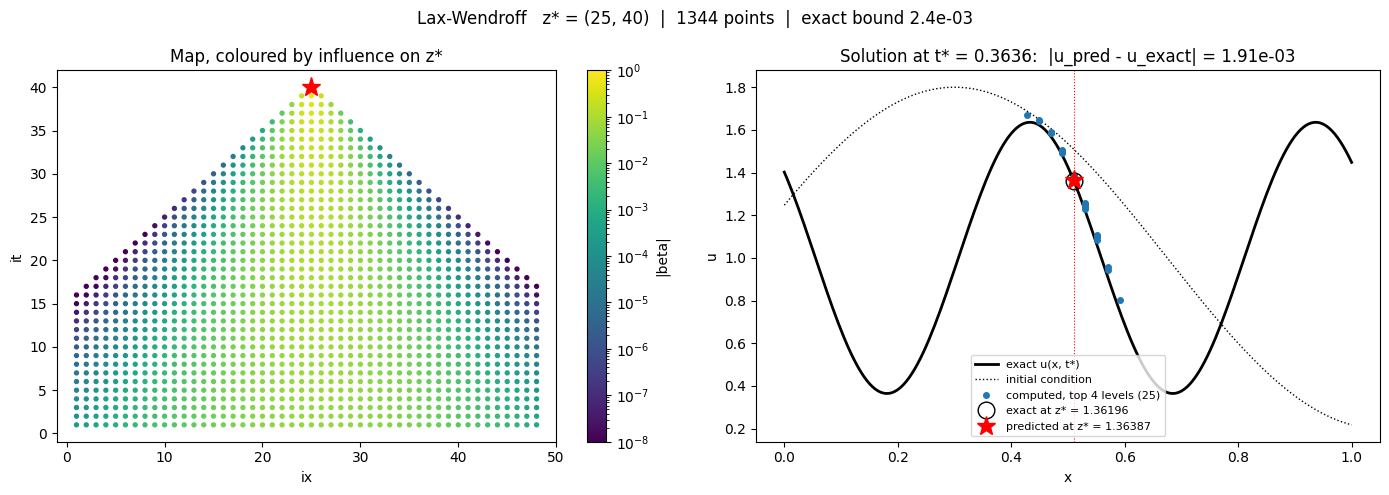

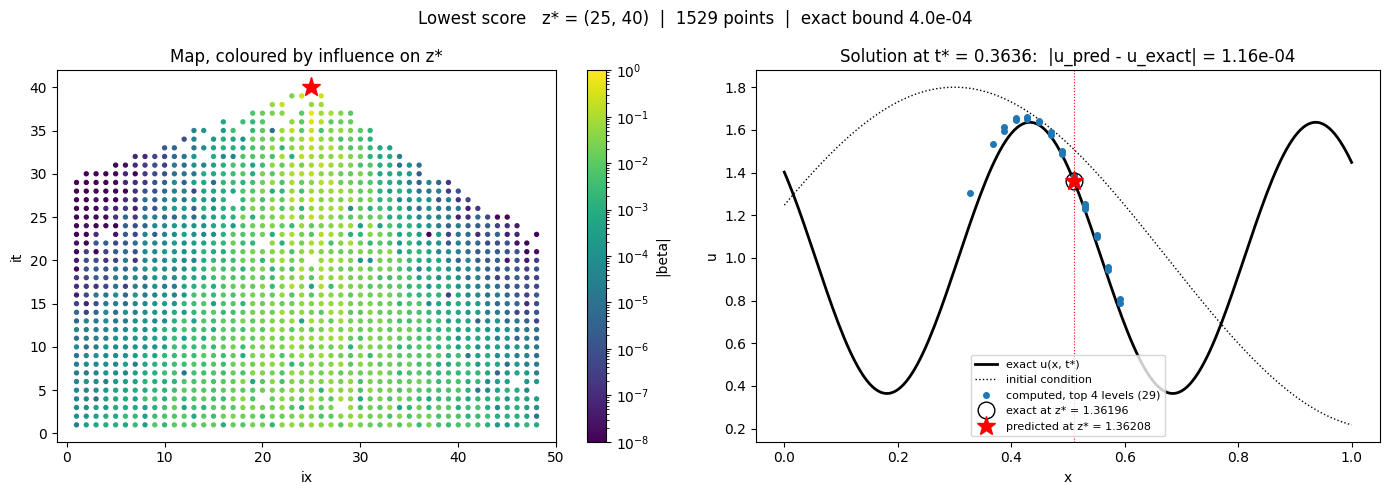

In [10]:
# ── One figure for any finished map (used for the baselines and the training videos) ──
#   left : the map, coloured by influence |beta| on z*
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("Map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4,
            label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"Solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

plot_map(build_map((25 , 40), lw), "Lax-Wendroff")
plot_map(build_map((25, 40), lowest_score), "Lowest score")

### Training helpers and callbacks
- `make_env`: one training environment (with the action mask and the episode monitor).
- `run_policy`: one episode where the policy takes its most likely pick every time; returns the finished map.
- `MapLogCallback`: logs points, score sum (both relative to LW) and the finish rate of the training episodes to TensorBoard.
- `SnapshotCallback`: every `every` steps, runs the current policy on one query, saves its map figure (cell 9) and keeps its numbers. These images become the training-progress video.

All take an environment class (`env_cls`), so the same helpers serve the multi-query environment later.
Check: a tiny run (2 environments, 2048 steps) to see that everything connects.

In [11]:
# ── Helpers for training: environment factory and one deterministic run of a trained policy ──
def make_env(queries, lam_range, seed, env_cls=MapEnv):
    def _init():
        env = Monitor(ActionMasker(env_cls(queries=queries, lam_range=lam_range), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* at a fixed lam, with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam_range=(lam, lam))
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: log map numbers of every finished training episode (mean of the last 100) ──
class MapLogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.hist = {"points_ratio": [], "score_ratio": [], "finished": []}

    def _on_step(self):
        for info in self.locals["infos"]:
            if "points_ratio" in info:                              # only at the end of an episode
                for k in self.hist:
                    self.hist[k].append(float(info[k]))
        for k, v in self.hist.items():
            if v:
                self.logger.record(f"map/{k}", np.mean(v[-100:]))
        return True

# ── Callback 2: every `every` steps, run the current policy on z_plot at a fixed lam, save the figure and the numbers ──
class SnapshotCallback(BaseCallback):
    def __init__(self, z_plot, lam, every, img_dir, env_cls=MapEnv):
        super().__init__()
        self.z_plot, self.lam, self.every, self.img_dir, self.env_cls = z_plot, lam, every, img_dir, env_cls
        self.last, self.hist, self.episodes = -every, [], 0

    def _on_step(self):
        self.episodes += sum("episode" in info for info in self.locals["infos"])   # maps finished in training
        if self.num_timesteps - self.last >= self.every:
            self.last = self.num_timesteps
            env = run_policy(self.model, self.z_plot, self.lam, self.env_cls)
            if env.info["finished"]:
                rep = report(env.m)
                plot_map(env.m, f"step {self.num_timesteps:,}  ({self.episodes} maps)  |  lam {self.lam:g}  |  return {env.ret:.2f}",
                         os.path.join(self.img_dir, f"map_{self.num_timesteps:09d}.png"))
            else:
                rep = {"points": env.info["points"], "error": np.nan, "bound": np.nan}
            self.hist.append({"step": self.num_timesteps, "episodes": self.episodes, "return": env.ret, **rep})
            print(f"step {self.num_timesteps:>10,} | {self.episodes:5d} maps: return {env.ret:7.2f} | "
                  f"{rep['points']} points | bound {rep['bound']:.1e} | finished {env.info['finished']}")
        return True

In [12]:
# ── Self-contained: the rules this cell needs (overrides any earlier, broken copies) ──
def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

assert callable(greedy_rule(1.0)), "greedy_rule is broken"
def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

### Training
MaskablePPO, $\gamma=1$, `gae_lambda` and `ent_coef` as set in `PPO_KW`. One query (`Z_TRAIN`), λ from `LAM_RANGE`.
Everything a run produces goes into `runs{month}-{day}/{run_name}/`: `config.json` (all settings), `images/` (snapshot figures + final map),
`checkpoints/` (models), `logs/` (TensorBoard), `snapshots.json` (return, points, error, bound at every snapshot).
The stencil cache is not copied to the workers; each fills its own.

In [13]:
# ══ Screening run (5M steps): same-level neighbours on both sides, IC peak at the middle, one seed ══
#   Compare with the old-window agent at the same number of steps (its 5M checkpoint), not with a 20M model.
#   8 workers: with both-sided cells each worker's stencil table takes ~1.5 GB of memory.
import json
from stable_baselines3.common.callbacks import CheckpointCallback

Z_TRAIN   = (25, 45)
QUERIES   = [Z_TRAIN]
LAM_RANGE = (1.0, 1.0)
LAM_PLOT  = 1.0
SEED      = 1
TOTAL     = 5_000_000
N_ENVS    = 8
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=0.97, learning_rate=3e-4, ent_coef=0.0)

run_name = f"{PROBLEM}_peak{X_PK:g}_same{SAME_LEVEL}_state{'X' if STATE_X else '0'}_stable_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM_RANGE[0]:g}-{LAM_RANGE[1]:g}_seed{SEED}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, ic=dict(C_BG=C_BG, A_W=A_W, L_W=L_W, X_PK=X_PK), same_level=SAME_LEVEL, alpha=alpha, T=T,
                   nx=nx, nt=nt, queries=QUERIES, lam_range=LAM_RANGE, eps=EPS, seed=SEED, total=TOTAL, n_envs=N_ENVS,
                   ppo=PPO_KW, K_COARSE=K_COARSE, N_OBS=N_OBS, window=dict(R_X=R_X, K_T=K_T, N_NB=N_NB, cells=WINDOW),
                   date=str(date.today())), f, indent=2)
print("run folder:", run_dir)

for z in QUERIES:
    n_lw(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, LAM_RANGE, seed=100 * SEED + i) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=SEED, verbose=0, device="cpu",
                    tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)
snap_cb = SnapshotCallback(Z_TRAIN, LAM_PLOT, every=SNAP_EVERY, img_dir=img_dir)
t0 = time.time()
try:
    model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
                callback=[MapLogCallback(), snap_cb,
                          CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
finally:
    vec.close()
    with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
        json.dump(snap_cb.hist, f, indent=1, default=float)
model.save(os.path.join(ckpt_dir, "ppo_final"))
print(f"training time: {(time.time() - t0) / 60:.0f} min")

# ── the trained agent, the rules, and how often each uses upwind (left) vs downwind (right) same-level neighbours ──
m = run_policy(model, Z_TRAIN, LAM_PLOT).m
plot_map(m, f"final  |  same-level {SAME_LEVEL}  |  lam {LAM_PLOT:g}", os.path.join(img_dir, "map_final.png"))
print(f"\nat {Z_TRAIN}, lam = {LAM_PLOT:g}:")
for name, mm in [("agent", m), ("LW", build_map(Z_TRAIN, lw)), ("lowest score", build_map(Z_TRAIN, lowest_score)),
                 ("greedy", build_map(Z_TRAIN, greedy_rule(LAM_PLOT)))]:
    rep = report(mm)
    print(f"{name:>13s}: return {-score_sum(mm) / EPS - LAM_PLOT * (rep['points'] - 1) / n_lw(Z_TRAIN):6.2f} | {rep['points']:5d} points | "
          f"bound {rep['bound']:.1e} | error {rep['error']:.1e} | same-level left / right {same_level_use(mm)}")

run folder: runs10-21\advection_peak0.3_same0_state0_stable_z25-45_lam1-1_seed1
step          8 |     0 maps: return  -23.37 | 1711 points | bound 2.2e-02 | finished True
step    250,008 |    24 maps: return  -10.07 | 1241 points | bound 9.1e-03 | finished True
step    500,008 |    56 maps: return  -10.26 | 1411 points | bound 9.1e-03 | finished True
step    750,008 |    88 maps: return   -8.12 | 1387 points | bound 7.1e-03 | finished True
step  1,000,008 |   120 maps: return   -7.32 | 1661 points | bound 6.2e-03 | finished True
step  1,250,008 |   144 maps: return   -6.63 | 1715 points | bound 5.6e-03 | finished True
step  1,500,008 |   176 maps: return   -6.50 | 1705 points | bound 5.3e-03 | finished True
step  1,750,008 |   208 maps: return   -5.92 | 1718 points | bound 4.9e-03 | finished True
step  2,000,008 |   232 maps: return   -5.37 | 1738 points | bound 4.2e-03 | finished True
step  2,250,008 |   264 maps: return   -4.84 | 1628 points | bound 3.8e-03 | finished True
step  2,50

NameError: name 'same_level_use' is not defined

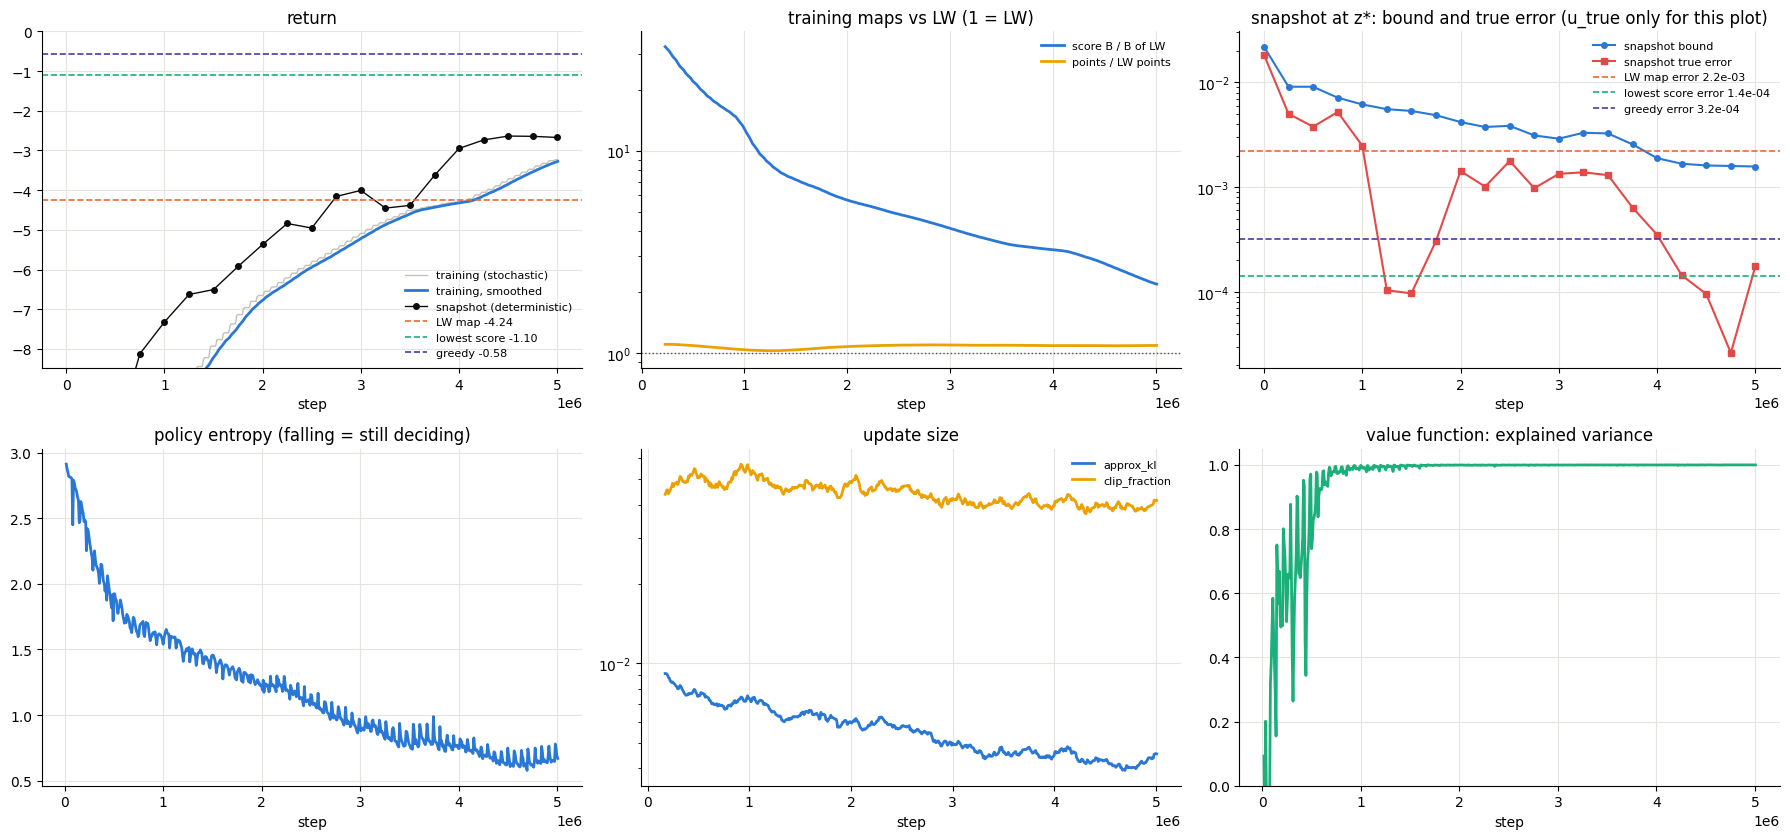

     rollout/ep_rew_mean:   -4.339 ->   -3.320 over the last 1M steps
         map/score_ratio:    3.252 ->    2.232 over the last 1M steps
        map/points_ratio:    1.087 ->    1.089 over the last 1M steps
      train/entropy_loss:   -0.775 ->   -0.670 over the last 1M steps


In [17]:
# ── Has the run converged? Training curves (tensorboard) + the deterministic snapshots, against the rules at Z_TRAIN ──
#   top:    return (training episodes, smoothed, and the snapshots) | score and points vs LW | snapshot bound and true error
#   bottom: PPO health: entropy (still falling = still deciding), approx KL and clip fraction, explained variance
#   converged ~ return, score ratio and entropy all flat over the last ~1M steps
import json, glob
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
RUN_DIR = os.path.join("runs10-21", "advection_peak0.3_same0_state0_stable_z25-45_lam1-1_seed1")
Z_RUN, LAM_RUN = (25, 45), 1.0

ea = EventAccumulator(sorted(glob.glob(os.path.join(RUN_DIR, "logs", "*")))[-1]); ea.Reload()
tb = lambda tag: (np.array([e.step for e in ea.Scalars(tag)]), np.array([e.value for e in ea.Scalars(tag)]))
smooth = lambda v, k=20: np.convolve(v, np.ones(k) / k, mode="valid") if len(v) > k else v
snaps = json.load(open(os.path.join(RUN_DIR, "snapshots.json")))
S = {k: np.array([s[k] for s in snaps], dtype=float) for k in ("step", "return", "points", "bound", "error")}

# the rules at the same query, as reference lines
base = {}
for name, rule in [("LW map", lw), ("lowest score", lowest_score), ("greedy", greedy_rule(LAM_RUN))]:
    mm = build_map(Z_RUN, rule); rep = report(mm)
    base[name] = dict(ret=-score_sum(mm) / EPS - LAM_RUN * (rep["points"] - 1) / n_lw(Z_RUN), **rep)
BC = {"LW map": "#eb6834", "lowest score": "#1baf7a", "greedy": "#4a3aa7"}

fig, ax = plt.subplots(2, 3, figsize=(18, 8.5))
st, v = tb("rollout/ep_rew_mean")
ax[0, 0].plot(st, v, color="#c3c2b7", lw=1, label="training (stochastic)")
ax[0, 0].plot(st[len(st) - len(smooth(v)):], smooth(v), color="#2a78d6", lw=2, label="training, smoothed")
ax[0, 0].plot(S["step"], S["return"], "o-", color="#0b0b0b", ms=4, lw=1, label="snapshot (deterministic)")
for n, b in base.items():
    ax[0, 0].axhline(b["ret"], color=BC[n], ls="--", lw=1.2, label=f"{n} {b['ret']:.2f}")
ax[0, 0].set_ylim(min(base["LW map"]["ret"], S["return"][-5:].min()) * 2, 0)
ax[0, 0].set_title("return"); ax[0, 0].legend(fontsize=8, frameon=False)

for tag, c, lab in [("map/score_ratio", "#2a78d6", "score B / B of LW"), ("map/points_ratio", "#eda100", "points / LW points")]:
    st, v = tb(tag)
    ax[0, 1].plot(st[len(st) - len(smooth(v)):], smooth(v), color=c, lw=2, label=lab)
ax[0, 1].axhline(1, color="#52514e", ls=":", lw=1); ax[0, 1].set_yscale("log")
ax[0, 1].set_title("training maps vs LW (1 = LW)"); ax[0, 1].legend(fontsize=8, frameon=False)

ax[0, 2].semilogy(S["step"], S["bound"], "o-", color="#2a78d6", ms=4, label="snapshot bound")
ax[0, 2].semilogy(S["step"], S["error"], "s-", color="#e34948", ms=4, label="snapshot true error")
for n, b in base.items():
    ax[0, 2].axhline(b["error"], color=BC[n], ls="--", lw=1.2, label=f"{n} error {b['error']:.1e}")
ax[0, 2].set_title("snapshot at z*: bound and true error (u_true only for this plot)"); ax[0, 2].legend(fontsize=8, frameon=False)

st, v = tb("train/entropy_loss"); ax[1, 0].plot(st, -v, color="#2a78d6", lw=2)
ax[1, 0].set_title("policy entropy (falling = still deciding)")
for tag, c in [("train/approx_kl", "#2a78d6"), ("train/clip_fraction", "#eda100")]:
    st, v = tb(tag); ax[1, 1].plot(st[len(st) - len(smooth(v)):], smooth(v), color=c, lw=2, label=tag.split("/")[1])
ax[1, 1].set_yscale("log"); ax[1, 1].set_title("update size"); ax[1, 1].legend(fontsize=8, frameon=False)
st, v = tb("train/explained_variance"); ax[1, 2].plot(st, v, color="#1baf7a", lw=2)
ax[1, 2].set_ylim(0, 1.05); ax[1, 2].set_title("value function: explained variance")
for a_ in ax.flat:
    a_.set_xlabel("step"); a_.spines[["top", "right"]].set_visible(False); a_.grid(True, color="#e5e4df", lw=0.8)
plt.tight_layout(); plt.show()

# ── Numbers: change over the last 1M steps (flat = converged) ──
for tag in ["rollout/ep_rew_mean", "map/score_ratio", "map/points_ratio", "train/entropy_loss"]:
    st, v = tb(tag)
    last, before = v[st >= st[-1] - 250_000].mean(), v[(st >= st[-1] - 1_250_000) & (st < st[-1] - 1_000_000)].mean()
    print(f"{tag:>24s}: {before:8.3f} -> {last:8.3f} over the last 1M steps")

In [18]:
# ══ Continue the advection run from ppo_final: same settings, same folder, step counter and tensorboard log continue ══
MORE = 5_000_000
RUN_DIR = os.path.join("runs10-21", "advection_peak0.3_same0_state0_stable_z25-45_lam1-1_seed1")
img_dir, ckpt_dir = os.path.join(RUN_DIR, "images"), os.path.join(RUN_DIR, "checkpoints")
cfg = json.load(open(os.path.join(RUN_DIR, "config.json")))
QUERIES, LAM_RANGE = [tuple(z) for z in cfg["queries"]], tuple(cfg["lam_range"])
Z_TRAIN, LAM_PLOT, SEED, N_ENVS = QUERIES[0], LAM_RANGE[0], cfg["seed"], cfg["n_envs"]

for z in QUERIES:
    n_lw(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, LAM_RANGE, seed=100 * SEED + 50 + i) for i in range(N_ENVS)])   # new seeds
model = MaskablePPO.load(os.path.join(ckpt_dir, "ppo_final"), env=vec, device="cpu",
                         tensorboard_log=os.path.join(RUN_DIR, "logs"))
snap_cb = SnapshotCallback(Z_TRAIN, LAM_PLOT, every=250_000, img_dir=img_dir)
snap_cb.hist = json.load(open(os.path.join(RUN_DIR, "snapshots.json")))          # keep the first run's snapshots
snap_cb.last = model.num_timesteps                                                # next snapshot 250k steps from here
t0 = time.time()
try:
    model.learn(total_timesteps=MORE, reset_num_timesteps=False, tb_log_name="ppo",
                callback=[MapLogCallback(), snap_cb,
                          CheckpointCallback(save_freq=max(1_000_000 // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
finally:
    vec.close()
    with open(os.path.join(RUN_DIR, "snapshots.json"), "w") as f:
        json.dump(snap_cb.hist, f, indent=1, default=float)
model.save(os.path.join(ckpt_dir, f"ppo_final_{model.num_timesteps // 1_000_000}M"))
print(f"training time: {(time.time() - t0) / 60:.0f} min, now at {model.num_timesteps:,} steps")

step  5,255,312 |    24 maps: return   -2.89 | 1748 points | bound 1.9e-03 | finished True
step  5,505,312 |    56 maps: return   -2.89 | 1763 points | bound 1.8e-03 | finished True
step  5,755,312 |    80 maps: return   -3.06 | 1765 points | bound 2.0e-03 | finished True
step  6,005,312 |   112 maps: return   -3.15 | 1757 points | bound 2.1e-03 | finished True
step  6,255,312 |   136 maps: return   -2.98 | 1756 points | bound 1.9e-03 | finished True
step  6,505,312 |   168 maps: return   -3.12 | 1748 points | bound 2.1e-03 | finished True
step  6,755,312 |   192 maps: return   -2.89 | 1793 points | bound 1.8e-03 | finished True
step  7,005,312 |   224 maps: return   -2.70 | 1793 points | bound 1.6e-03 | finished True
step  7,255,312 |   253 maps: return   -2.71 | 1789 points | bound 1.6e-03 | finished True
step  7,505,312 |   280 maps: return   -2.74 | 1798 points | bound 1.7e-03 | finished True
step  7,755,312 |   309 maps: return   -2.81 | 1810 points | bound 1.7e-03 | finished True

In [29]:
# ══ Comparisons for the advection agent (trained only at Z_TRAIN = (25, 45), 10M steps) ══
# ── C1. Every map method on the training query + 9 unseen queries on both sides of X0 (kept for the figures below) ──
from collections import Counter
from math import erf
from sb3_contrib import MaskablePPO
RUN_DIR = os.path.join("runs10-21", "advection_peak0.3_same0_state0_stable_z25-45_lam1-1_seed1")
agent   = MaskablePPO.load(os.path.join(RUN_DIR, "checkpoints", "ppo_final_10M"), device="cpu")
Z_TRAIN, LAM = (25, 45), 1.0
QUERIES_TEST = [(ix, it) for it in (25, 40, 55) for ix in (12, 25, 37)]
Z_ALL = [Z_TRAIN] + QUERIES_TEST

def agent_map(z):
    env = run_policy(agent, z, LAM)
    assert env.info["finished"], f"the agent did not finish the map at {z}"
    return env.m

RULES = {"LW map": lambda z: build_map(z, lw), "lowest score": lambda z: build_map(z, lowest_score),
         "greedy": lambda z: build_map(z, greedy_rule(LAM)), "agent": agent_map}
MAPS, REP = {}, {}                                       # MAPS[z][name] = map, REP[z][name] = points, error, bound, return
t0 = time.time()
for z in Z_ALL:
    MAPS[z], REP[z] = {}, {}
    for name, make in RULES.items():
        m = make(z); rep = report(m)
        MAPS[z][name] = m
        REP[z][name] = dict(points=rep["points"], error=rep["error"], bound=rep["bound"],
                            ret=-score_sum(m) / EPS - LAM * (rep["points"] - 1) / n_lw(z))
    print(f"z* = {z}: done ({time.time() - t0:.0f} s)")

z* = (25, 45): done (6 s)
z* = (12, 25): done (8 s)
z* = (25, 25): done (10 s)
z* = (37, 25): done (12 s)
z* = (12, 40): done (17 s)
z* = (25, 40): done (21 s)
z* = (37, 40): done (26 s)
z* = (12, 55): done (32 s)
z* = (25, 55): done (39 s)
z* = (37, 55): done (46 s)


In [30]:
# ── C2. Is it one stencil again? Each of the agent's 8 most used stencils, used at every point ──
#   fixed stencil = the same window cells at every point (LW where they are not admissible: next to the walls / IC)
#   "best fixed" = lowest exact bound over the unseen queries (an oracle choice: it uses u_true, the agent never does)
def stencil_cells(p, nbs):
    """Window cells of p's stencil, or None next to the walls / IC (cells there are moved onto the known data)."""
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None

def fixed_rule(cells):
    def choose(m, p):
        sets, _, _ = allowed_sets(m, p)
        return [place(p, k) for k in cells] if cells in sets else lw(m, p)
    return choose

count = Counter(c for z in Z_ALL for p, (nbs, w) in MAPS[z]["agent"]["stencil"].items()
                if (c := stencil_cells(p, nbs)) is not None)
CANDS = [c for c, _ in count.most_common(8)]
FIX, t0 = {}, time.time()
for i, c in enumerate(CANDS):
    FIX[c] = {}
    for z in Z_ALL:
        rep = report(build_map(z, fixed_rule(c)))
        FIX[c][z] = dict(points=rep["points"], error=rep["error"], bound=rep["bound"])
    print(f"fixed stencil #{i + 1}: done ({time.time() - t0:.0f} s)")
gm = lambda v: float(np.exp(np.mean(np.log(v))))
rel = lambda reps, k: gm([reps[z][k] / REP[z]["LW map"][k] for z in QUERIES_TEST])     # geometric mean / LW map, unseen
BEST = min(CANDS, key=lambda c: rel(FIX[c], "bound"))
for z in Z_ALL:
    REP[z]["best fixed"] = FIX[BEST][z]

fixed stencil #1: done (4 s)
fixed stencil #2: done (8 s)
fixed stencil #3: done (12 s)
fixed stencil #4: done (16 s)
fixed stencil #5: done (20 s)
fixed stencil #6: done (24 s)
fixed stencil #7: done (29 s)
fixed stencil #8: done (33 s)


In [31]:
# ── C3. Classical solvers at every query: true error at z* and evaluated points, grids 1-4x ──
#   FD-3 | LW (with the a a' u_x dt^2/2 term) | CN | FD-5 + RK4 | WENO5 + RK3 (flux a u, Lax-Friedrichs splitting, ghosts from u_true)
#   evaluated points = grid values in z*'s dependency cone (RK: x stages; CN: the whole row). Map methods also pay for the guess.
from scipy.linalg import solve_banded
_gd = _gs.derivative()

def _weno5(vm2, vm1, v0, vp1, vp2):
    q0, q1, q2 = (2 * vm2 - 7 * vm1 + 11 * v0) / 6, (-vm1 + 5 * v0 + 2 * vp1) / 6, (2 * v0 + 5 * vp1 - vp2) / 6
    b0 = 13 / 12 * (vm2 - 2 * vm1 + v0)**2 + 0.25 * (vm2 - 4 * vm1 + 3 * v0)**2
    b1 = 13 / 12 * (vm1 - 2 * v0 + vp1)**2 + 0.25 * (vm1 - vp1)**2
    b2 = 13 / 12 * (v0 - 2 * vp1 + vp2)**2 + 0.25 * (3 * v0 - 4 * vp1 + vp2)**2
    w0, w1, w2 = 0.1 / (1e-6 + b0)**2, 0.6 / (1e-6 + b1)**2, 0.3 / (1e-6 + b2)**2
    return (w0 * q0 + w1 * q1 + w2 * q2) / (w0 + w1 + w2)

def rhs(u, h, t, scheme):
    n = len(u)
    if scheme == "WENO5 + RK3":
        ue = np.r_[u_true(-h * np.arange(3, 0, -1), t), u, u_true(1 + h * np.arange(1, 4), t)]
        ae = speed(h * (np.arange(n + 6) - 3)); am = np.abs(ae).max()
        fp, fm = 0.5 * (ae * ue + am * ue), 0.5 * (ae * ue - am * ue)        # a u_x = (a u)_x - a' u
        j = np.arange(2, n + 3)
        F = _weno5(fp[j - 2], fp[j - 1], fp[j], fp[j + 1], fp[j + 2]) + _weno5(fm[j + 3], fm[j + 2], fm[j + 1], fm[j], fm[j - 1])
        c = np.arange(3, n + 3)
        du = -(F[1:] - F[:-1]) / h + C_OU * u + alpha * (-ue[c + 2] + 16 * ue[c + 1] - 30 * ue[c] + 16 * ue[c - 1] - ue[c - 2]) / (12 * h**2)
    else:
        u2, u1 = np.zeros(n), np.zeros(n)
        u2[1:-1], u1[1:-1] = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
        u2[2:-2] = (-u[4:] + 16 * u[3:-1] - 30 * u[2:-2] + 16 * u[1:-3] - u[:-4]) / 12
        u1[2:-2] = (-u[4:] + 8 * u[3:-1] - 8 * u[1:-3] + u[:-4]) / 12
        du = alpha * u2 / h**2 - speed(np.arange(n) * h) * u1 / h
    du[0], du[-1] = _gd(t)
    return du

def classical(scheme, k, z):
    """(evaluated points, true error at z*) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    t_star, ix = z[1] * dt, z[0] * k
    u = u0(np.arange(n) * h)
    if scheme == "WENO5 + RK3":
        steps = int(np.ceil(t_star / min(0.4 * h / A_MAX, 0.2 * h**2 / alpha))); tau_k = t_star / steps
    else:
        tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2
        steps = round(t_star / tau_k)
    r = alpha * tau_k / h**2
    for j in range(steps):
        t, t1 = j * tau_k, (j + 1) * tau_k
        if scheme == "WENO5 + RK3":
            u1 = u + tau_k * rhs(u, h, t, scheme)
            u2 = 0.75 * u + 0.25 * (u1 + tau_k * rhs(u1, h, t1, scheme))
            u = u / 3 + 2 / 3 * (u2 + tau_k * rhs(u2, h, t + tau_k / 2, scheme))
        elif scheme == "FD-5 + RK4":
            k1 = rhs(u, h, t, scheme); k2 = rhs(u + tau_k * k1 / 2, h, t + tau_k / 2, scheme)
            k3 = rhs(u + tau_k * k2 / 2, h, t + tau_k / 2, scheme); k4 = rhs(u + tau_k * k3, h, t1, scheme)
            u = u + tau_k * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            nu = speed(np.arange(1, n - 1) * h) * tau_k / h
            d2, d1 = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
            new = u.copy()
            if scheme == "FD-3":
                new[1:-1] = u[1:-1] + r * d2 - nu * d1
            elif scheme == "LW":
                new[1:-1] = u[1:-1] + (r + nu**2 / 2) * d2 - nu * (1 - C_OU * tau_k / 2) * d1
            elif scheme == "CN":
                lo, up = -r / 2 - nu / 4, -r / 2 + nu / 4
                b = u[1:-1] + r / 2 * d2 - nu / 2 * d1
                b[0] -= lo[0] * g_left(t1); b[-1] -= up[-1] * g_right(t1)
                ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], 1 + r, lo[1:]
                new[1:-1] = solve_banded((1, 1), ab, b)
            new[0], new[-1] = g_left(t1), g_right(t1)
            u = new
    err = abs(u[ix] - Ug(z))
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8, "WENO5 + RK3": 9}.get(scheme)
    if spread is None:
        pts = (n - 2) * steps
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        pts *= {"FD-5 + RK4": 4, "WENO5 + RK3": 3}.get(scheme, 1)
    return pts, err

SCHEMES = ["FD-3", "LW", "CN", "FD-5 + RK4", "WENO5 + RK3"]
CL, GUESS_COST, t0 = {}, {}, time.time()
for z in Z_ALL:
    CL[z] = {s: [classical(s, k, z) for k in (1, 2, 3, 4)] for s in SCHEMES}      # [(points, error)] for grids 1-4x
    GUESS_COST[z] = (len(xc) - 2) * int(np.ceil(z[1] * dt / tau))                  # guess levels up to t*, added to every map
    print(f"z* = {z}: done ({time.time() - t0:.0f} s)")

z* = (25, 45): done (1 s)
z* = (12, 25): done (1 s)
z* = (25, 25): done (2 s)
z* = (37, 25): done (2 s)
z* = (12, 40): done (3 s)
z* = (25, 40): done (4 s)
z* = (37, 40): done (4 s)
z* = (12, 55): done (5 s)
z* = (25, 55): done (6 s)
z* = (37, 55): done (7 s)


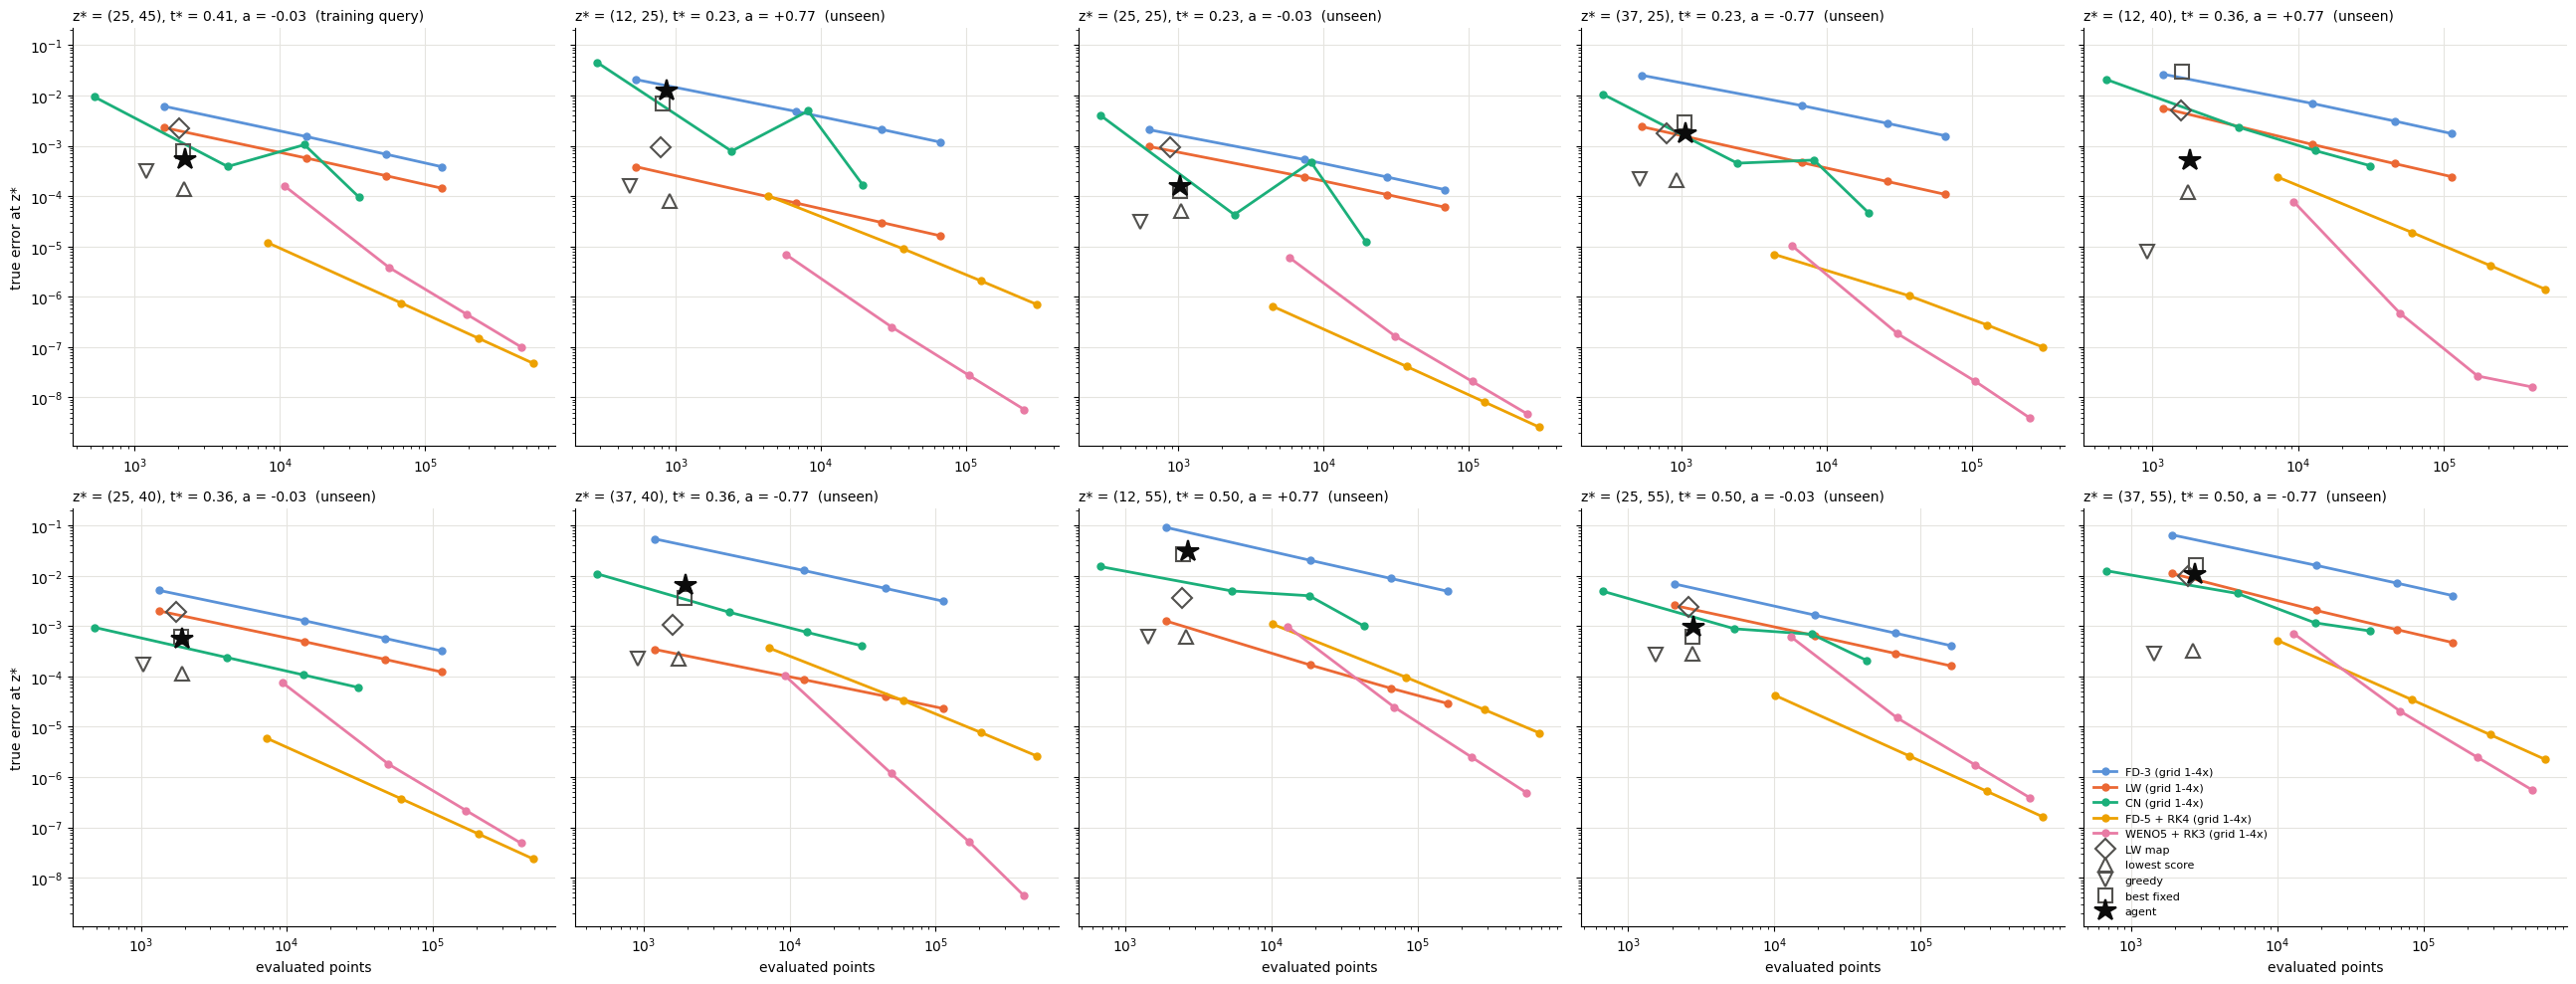

In [32]:
# ── P1. True error at z* vs evaluated points, every query: classical solvers (grids 1-4x) and the map methods ──
COL = {"FD-3": "#5a92d8", "LW": "#eb6834", "CN": "#1baf7a", "FD-5 + RK4": "#eda100", "WENO5 + RK3": "#e87ba4"}
MK  = {"LW map": "D", "lowest score": "^", "greedy": "v", "best fixed": "s", "agent": "*"}

def error_points_panel(ax, z, legend=False):
    for s in SCHEMES:
        ax.loglog(*zip(*CL[z][s]), "o-", color=COL[s], lw=2, ms=5, label=f"{s} (grid 1-4x)")
    for name, mk in MK.items():
        r, ag = REP[z][name], name == "agent"
        ax.loglog(r["points"] + GUESS_COST[z], r["error"], mk, color="#0b0b0b" if ag else "#52514e",
                  ms=16 if ag else 10, mfc="#0b0b0b" if ag else "none", mew=1.5, label=name)
    tag = "training query" if z == Z_TRAIN else "unseen"
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}, a = {float(speed(z[0] * dx)):+.2f}  ({tag})", loc="left", fontsize=10)
    ax.grid(True, which="major", color="#e5e4df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
    if legend:
        ax.legend(fontsize=8, frameon=False, loc="lower left")

fig, axes = plt.subplots(2, 5, figsize=(26, 10), sharey=True)
for ax, z in zip(axes.flat, Z_ALL):
    error_points_panel(ax, z, legend=(z == Z_ALL[-1]))
for ax in axes[1]:
    ax.set_xlabel("evaluated points")
for ax in axes[:, 0]:
    ax.set_ylabel("true error at z*")
plt.tight_layout(); plt.show()

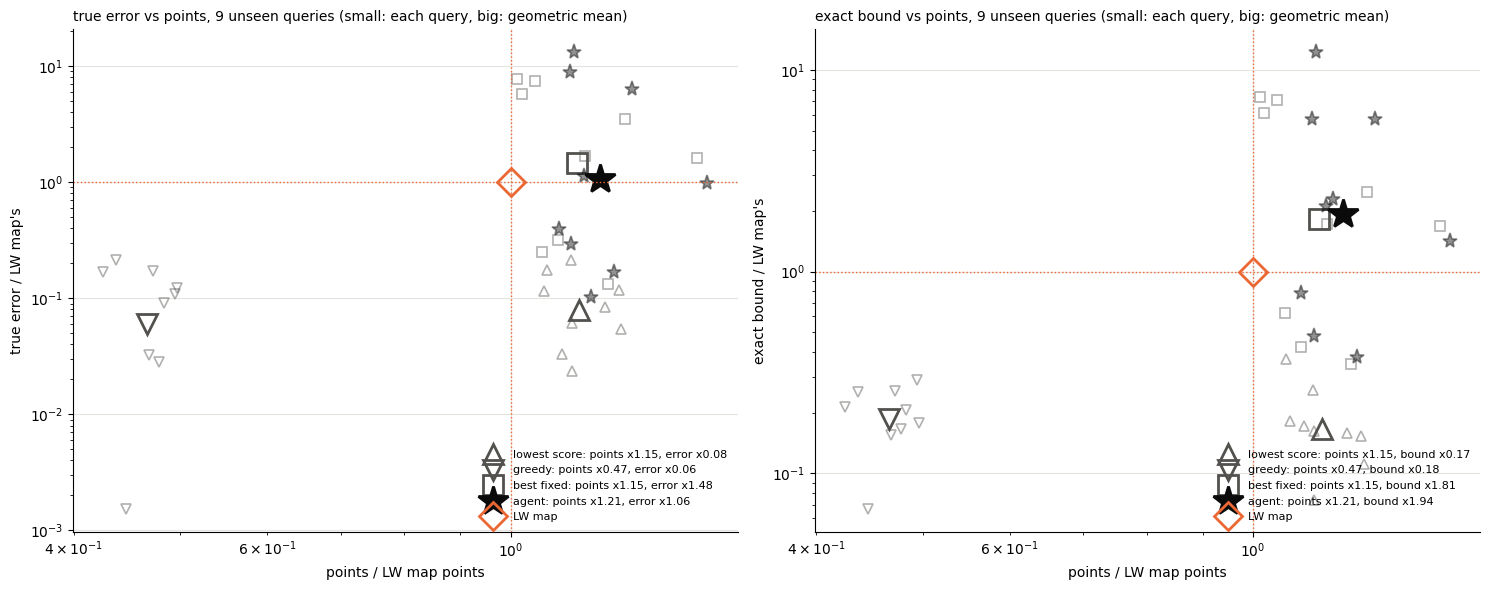

unseen queries (9): each / LW map (geometric mean); wins = true error below the LW map's
   lowest score: points x1.15 | bound x0.17 | error x0.08 | wins 9/9
         greedy: points x0.47 | bound x0.18 | error x0.06 | wins 9/9
     best fixed: points x1.15 | bound x1.81 | error x1.48 | wins 3/9
          agent: points x1.21 | bound x1.94 | error x1.06 | wins 5/9


In [33]:
# ── P2. All unseen queries on one plot: each map method relative to the LW map of the same query (LW map = 1, 1) ──
#   small markers: one per query; big markers: geometric mean over the unseen queries. Lower left = better than LW.
METHODS = ["lowest score", "greedy", "best fixed", "agent"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, k in zip(axes, ("error", "bound")):
    for name in METHODS:
        ag = name == "agent"
        px = [REP[z][name]["points"] / REP[z]["LW map"]["points"] for z in QUERIES_TEST]
        py = [REP[z][name][k] / REP[z]["LW map"][k] for z in QUERIES_TEST]
        c = "#0b0b0b" if ag else "#52514e"
        ax.loglog(px, py, MK[name], color=c, ms=11 if ag else 7, mfc=c if ag else "none", mew=1.2, alpha=0.45)
        ax.loglog(gm(px), gm(py), MK[name], color=c, ms=22 if ag else 14, mfc=c if ag else "none", mew=2,
                  label=f"{name}: points x{gm(px):.2f}, {k} x{gm(py):.2f}")
    ax.loglog(1, 1, "D", color="#eb6834", ms=14, mfc="none", mew=2, label="LW map")
    ax.axhline(1, color="#eb6834", ls=":", lw=1); ax.axvline(1, color="#eb6834", ls=":", lw=1)
    ax.set_xlabel("points / LW map points"); ax.set_ylabel(f"{'true error' if k == 'error' else 'exact bound'} / LW map's")
    ax.set_title(f"{'true error' if k == 'error' else 'exact bound'} vs points, {len(QUERIES_TEST)} unseen queries "
                 "(small: each query, big: geometric mean)", loc="left", fontsize=10)
    ax.grid(True, which="major", color="#e5e4df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print(f"unseen queries ({len(QUERIES_TEST)}): each / LW map (geometric mean); wins = true error below the LW map's")
for name in METHODS:
    wins = sum(REP[z][name]["error"] < REP[z]["LW map"]["error"] for z in QUERIES_TEST)
    print(f"  {name:>13s}: points x{rel({z: REP[z][name] for z in Z_ALL}, 'points'):.2f} | "
          f"bound x{rel({z: REP[z][name] for z in Z_ALL}, 'bound'):.2f} | error x{rel({z: REP[z][name] for z in Z_ALL}, 'error'):.2f} | "
          f"wins {wins}/{len(QUERIES_TEST)}")

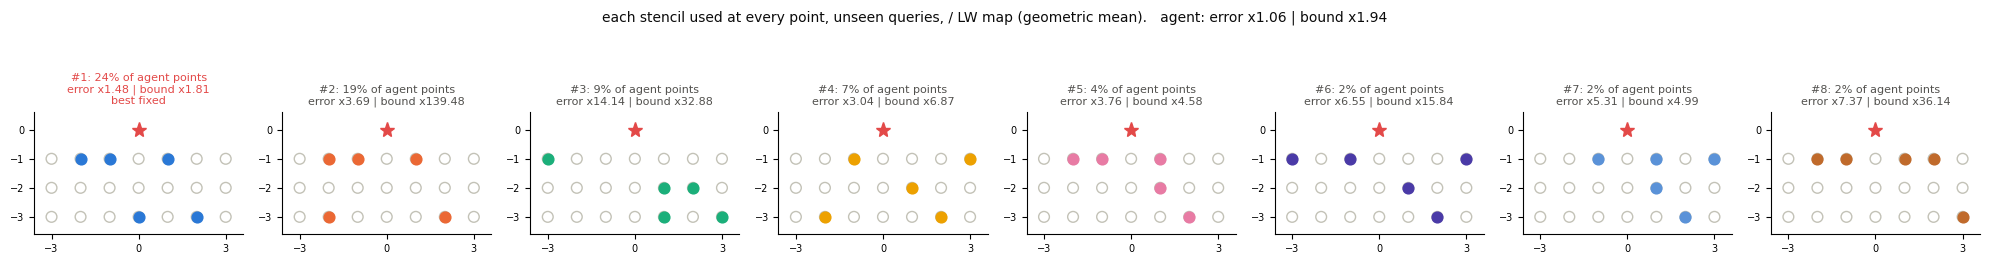

best fixed stencil (#1): true error below the agent's at 5/9 unseen queries


In [34]:
# ── P3. The agent's 8 most used stencils, each used at every point: how close does one stencil get to the agent? ──
TOP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#5a92d8", "#c06a2b"]
total = sum(count.values())
agent_err = rel({z: REP[z]["agent"] for z in Z_ALL}, "error")
fig, axes = plt.subplots(1, len(CANDS), figsize=(2.5 * len(CANDS), 3.1))
for i, (ax, c) in enumerate(zip(axes, CANDS)):
    ax.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors="#c3c2b7")
    ax.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
    ax.plot(0, 0, "*", color="#e34948", ms=11)
    ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 0.6); ax.set_aspect("equal")
    ax.set_xticks([-3, 0, 3]); ax.set_yticks([0, -1, -2, -3]); ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"#{i + 1}: {count[c] / total:.0%} of agent points\nerror x{rel(FIX[c], 'error'):.2f} | bound x{rel(FIX[c], 'bound'):.2f}"
                 + ("\nbest fixed" if c == BEST else ""), fontsize=8, color="#e34948" if c == BEST else "#52514e")
fig.suptitle(f"each stencil used at every point, unseen queries, / LW map (geometric mean).   "
             f"agent: error x{agent_err:.2f} | bound x{rel({z: REP[z]['agent'] for z in Z_ALL}, 'bound'):.2f}",
             fontsize=10, color="#0b0b0b")
plt.tight_layout(); plt.show()

best_beats = sum(FIX[BEST][z]["error"] < REP[z]["agent"]["error"] for z in QUERIES_TEST)
print(f"best fixed stencil (#{CANDS.index(BEST) + 1}): true error below the agent's at {best_beats}/{len(QUERIES_TEST)} unseen queries")

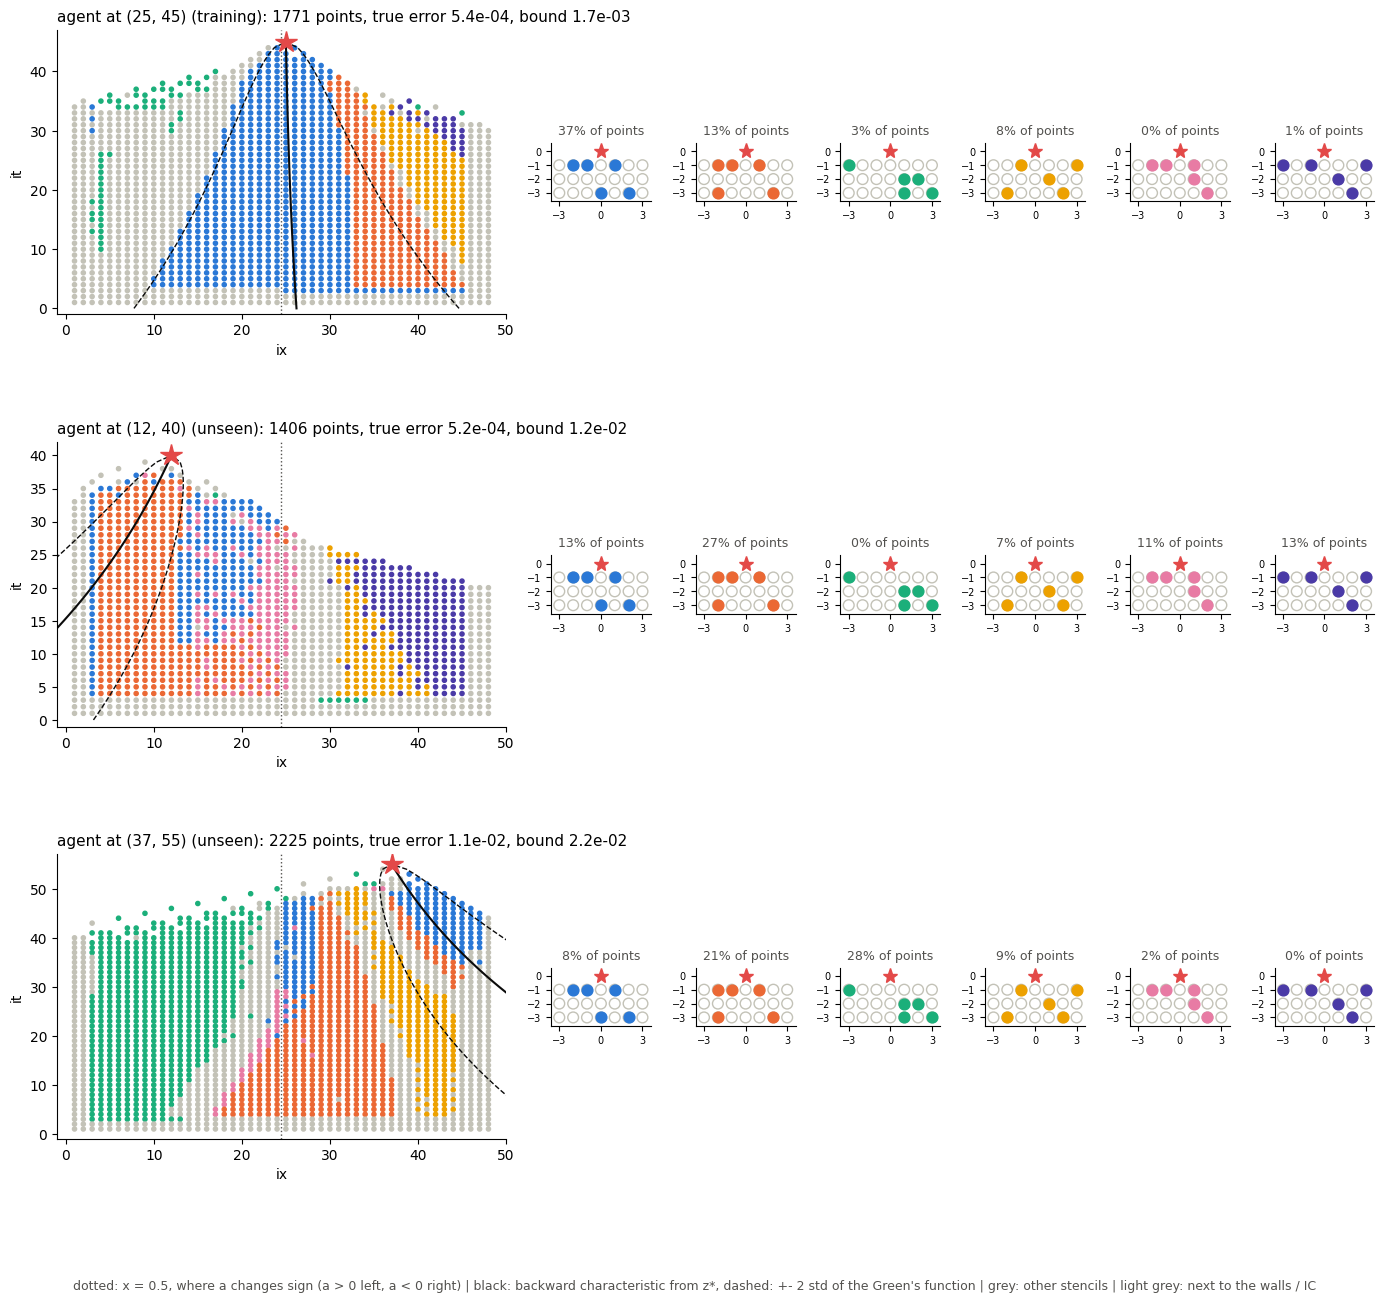

In [35]:
# ── P4. Which stencil the agent uses where, at the training query and two unseen ones, with the backward characteristic ──
#   same colour = same stencil in every row (the 6 most used over all queries); grey: other stencils; light grey: next to the walls / IC
#   black line: the backward characteristic from z* (the centre of the Green's function); dashed: +- 2 standard deviations
OTHER, EDGE = "#c3c2b7", "#e5e4df"
TOP6  = CANDS[:6]
color = {c: TOP_COLORS[i] for i, c in enumerate(TOP6)}
Z_MAP = [Z_TRAIN, (12, 40), (37, 55)]

fig = plt.figure(figsize=(17, 4.8 * len(Z_MAP)))
gs_ = fig.add_gridspec(len(Z_MAP), 7, width_ratios=[4.5, 1, 1, 1, 1, 1, 1], hspace=0.45, wspace=0.3)
for row, z in enumerate(Z_MAP):
    m = MAPS[z]["agent"]
    cells = {p: stencil_cells(p, nbs) for p, (nbs, w) in m["stencil"].items()}
    used = Counter(c for c in cells.values() if c is not None); n_used = sum(used.values())
    ax = fig.add_subplot(gs_[row, 0])
    P = np.array(list(cells))
    ax.scatter(P[:, 0], P[:, 1], s=9, c=[EDGE if c is None else color.get(c, OTHER) for c in cells.values()])
    lv = np.arange(z[1] + 1); tau_ = (z[1] - lv) * dt
    mid = (X0 + (z[0] * dx - X0) * np.exp(-C_OU * tau_)) / dx
    sd  = np.sqrt(alpha * (1 - np.exp(-2 * C_OU * tau_)) / C_OU) / dx
    ax.plot(mid, lv, "-", color="#0b0b0b", lw=1.5)
    ax.plot(mid - 2 * sd, lv, "--", color="#0b0b0b", lw=1); ax.plot(mid + 2 * sd, lv, "--", color="#0b0b0b", lw=1)
    ax.axvline(X0 / dx, color="#52514e", ls=":", lw=1)
    ax.plot(*z, "*", color="#e34948", ms=16)
    r = REP[z]["agent"]
    ax.set_xlim(-1, nx); ax.set_ylim(-1, z[1] + 2); ax.set_xlabel("ix"); ax.set_ylabel("it")
    ax.set_title(f"agent at {z} ({'training' if z == Z_TRAIN else 'unseen'}): {r['points']} points, "
                 f"true error {r['error']:.1e}, bound {r['bound']:.1e}", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    for i, c in enumerate(TOP6):
        g_ = fig.add_subplot(gs_[row, i + 1])
        g_.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors=OTHER)
        g_.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
        g_.plot(0, 0, "*", color="#e34948", ms=11)
        g_.set_xlim(-3.6, 3.6); g_.set_ylim(-3.6, 0.6); g_.set_aspect("equal")
        g_.set_xticks([-3, 0, 3]); g_.set_yticks([0, -1, -2, -3]); g_.tick_params(labelsize=7)
        g_.set_title(f"{used[c] / n_used:.0%} of points", fontsize=9, color="#52514e")
        g_.spines[["top", "right"]].set_visible(False)
fig.text(0.5, 0.005, f"dotted: x = {X0:g}, where a changes sign (a > 0 left, a < 0 right) | black: backward characteristic from z*, "
         "dashed: +- 2 std of the Green's function | grey: other stencils | light grey: next to the walls / IC",
         ha="center", fontsize=9, color="#52514e")
plt.show()

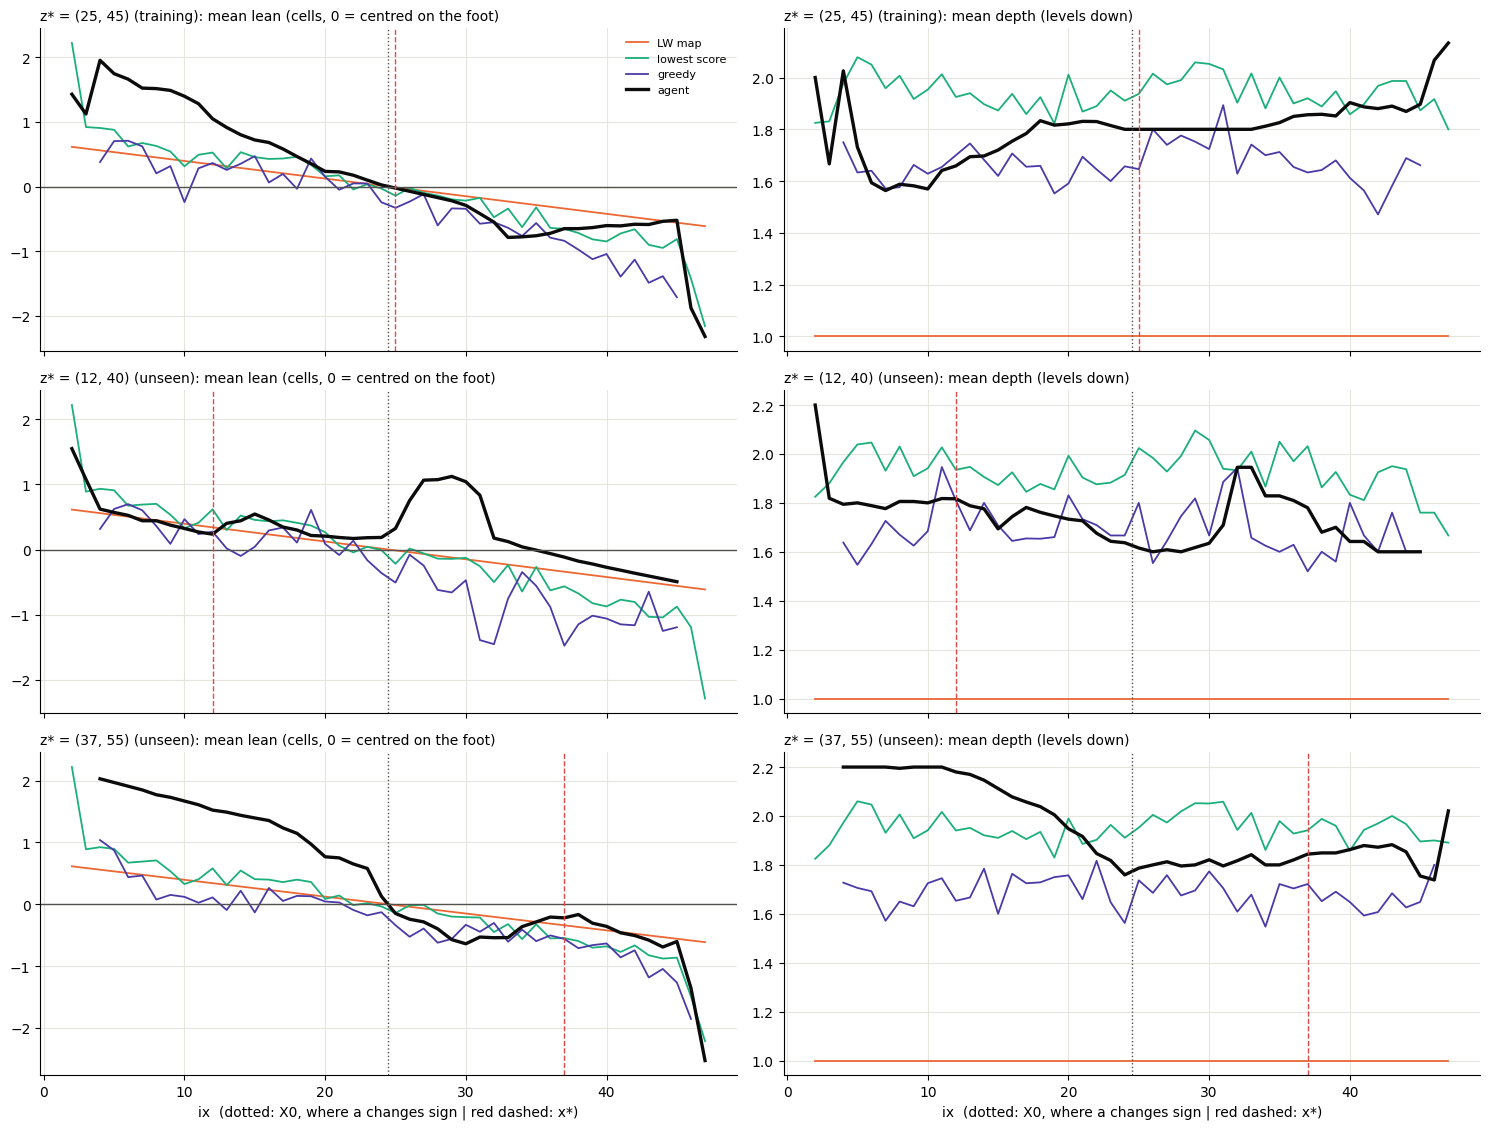

In [36]:
# ── P5. Does the stencil follow the characteristic? Mean lean and depth per column, every method, at z* ──
#   lean  = mean over the stencil of xi_q / dx, xi_q = dx_q - a(x_p) dt_q: the stencil centre's offset from the foot of the
#           characteristic through p (0 = centred on the foot). The LW map's lean is a dt / dx: centred below p, no lean.
#   depth = mean number of levels down of the stencil's cells
def lean_depth(m):
    out = []
    for p, (nbs, w) in m["stencil"].items():
        if any(is_known(q) for q in nbs):                            # next to the walls / IC: cells moved onto the data
            continue
        DX = np.array([q[0] - p[0] for q in nbs]) * dx
        DT = np.array([q[1] - p[1] for q in nbs]) * dt
        out.append((p[0], np.mean(DX - a_build(p) * DT) / dx, -np.mean(DT) / dt))
    return np.array(out)

COLN = {"LW map": "#eb6834", "lowest score": "#1baf7a", "greedy": "#4a3aa7", "agent": "#0b0b0b"}
fig, axes = plt.subplots(len(Z_MAP), 2, figsize=(15, 3.8 * len(Z_MAP)), sharex=True)
for row, z in enumerate(Z_MAP):
    for name, c in COLN.items():
        D = lean_depth(MAPS[z][name]); cols = np.unique(D[:, 0])
        for col, k in enumerate((1, 2)):
            axes[row, col].plot(cols, [D[D[:, 0] == i, k].mean() for i in cols], "-", color=c,
                                lw=2.4 if name == "agent" else 1.3, label=name)
    axes[row, 0].axhline(0, color="#52514e", lw=1)
    for col, t in enumerate(("mean lean (cells, 0 = centred on the foot)", "mean depth (levels down)")):
        ax = axes[row, col]
        ax.axvline(X0 / dx, color="#52514e", ls=":", lw=1); ax.axvline(z[0], color="#e34948", ls="--", lw=1)
        ax.set_title(f"z* = {z} ({'training' if z == Z_TRAIN else 'unseen'}): {t}", loc="left", fontsize=10)
        ax.grid(True, color="#e5e4df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(fontsize=8, frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("ix  (dotted: X0, where a changes sign | red dashed: x*)")
plt.tight_layout(); plt.show()

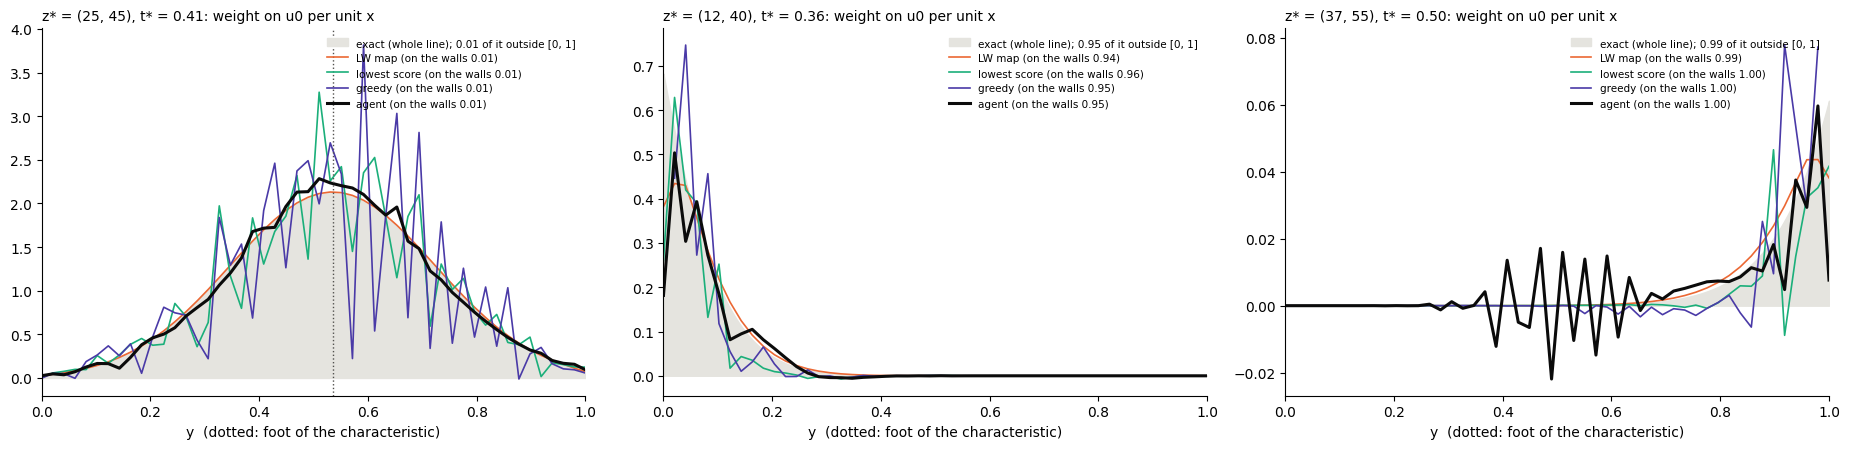

In [37]:
# ── P6. Green's function: the weight each map puts on the initial data, vs the exact one ──
#   u_hat(z*) = sum over known points q of G_q u_q;  G_q = sum of beta_p w_pq over the points p that use q (IC row and walls)
#   exact (whole line): Gaussian with mean X0 + (x* - X0) e^{-C t*} (characteristic foot), variance alpha (1 - e^{-2C t*}) / C;
#   the bounded problem differs only where it reaches the walls (that weight goes to the wall data).
#   NB: the 3 Taylor conditions roughly fix the total weight, centre and spread for ANY map: compare the SHAPE.
def known_weights(m):
    G = {}
    for p, (nbs, w) in m["stencil"].items():
        for q, wq in zip(nbs, w):
            if is_known(q):
                G[q] = G.get(q, 0.0) + m["beta"][p] * wq
    return G

yf = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, len(Z_MAP), figsize=(6.2 * len(Z_MAP), 4.6))
for ax, z in zip(axes, Z_MAP):
    t_ = z[1] * dt
    mu, var = X0 + (z[0] * dx - X0) * np.exp(-C_OU * t_), alpha * (1 - np.exp(-2 * C_OU * t_)) / C_OU
    out = 1 - 0.5 * (erf((1 - mu) / np.sqrt(2 * var)) - erf(-mu / np.sqrt(2 * var)))
    ax.fill_between(yf, np.exp(-(yf - mu)**2 / (2 * var)) / np.sqrt(2 * np.pi * var), color="#e5e4df",
                    label=f"exact (whole line); {out:.2f} of it outside [0, 1]")
    for name, c in COLN.items():
        G = known_weights(MAPS[z][name])
        ic = sorted((q[0], gq) for q, gq in G.items() if q[1] == 0)
        wall = sum(gq for q, gq in G.items() if q[1] > 0)
        ax.plot([i * dx for i, _ in ic], [gq / dx for _, gq in ic], "-", color=c, lw=2.2 if name == "agent" else 1.2,
                label=f"{name} (on the walls {wall:.2f})")
    ax.axvline(mu, color="#52514e", ls=":", lw=1)
    ax.set_title(f"z* = {z}, t* = {t_:.2f}: weight on u0 per unit x", loc="left", fontsize=10)
    ax.set_xlabel("y  (dotted: foot of the characteristic)"); ax.set_xlim(0, 1)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=7.5, frameon=False, loc="upper right")
plt.tight_layout(); plt.show()